les premières étapes d’un modèle de notation interne

In [33]:

import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
sns.set(style="whitegrid", palette="muted")
from scipy import stats
from scipy.stats import chi2_contingency, pointbiserialr
from scipy.stats import ttest_ind
from sklearn.impute import SimpleImputer
import warnings
warnings.filterwarnings('ignore')
import importlib
import sys

# Forcer le rechargement des modules sklearn et imblearn
for mod_name in list(sys.modules.keys()):
    if 'sklearn' in mod_name or 'imblearn' in mod_name:
        del sys.modules[mod_name]

plt.rcParams['figure.figsize'] = [12, 8]
plt.rcParams['figure.dpi'] = 100

# ETAPE 1 : DATA QUALITY CHECK & ANALYSE EXPLORATOIRE

1. Compréhension de la base de données

Cette section vise à explorer la structure globale de la base de données,
à identifier les types de variables disponibles et à comprendre les
dimensions du risque de crédit couvertes par les données.

In [34]:
# Chargement des données 
print("=== CHARGEMENT DES DONNEES ===\n")
df = pd.read_excel("base_SNI.xlsx",sheet_name=1)
n_obs, n_vars = df.shape
print(f"Nombre d'observations (clients) : {n_obs}")
print(f"Nombre de variables : {n_vars}")
print(f"\nApercu des colonnes:")
print(df.columns.tolist())
print("Aperçu des données :")
print(df.head(), "\n")


#Compréhension et typologie des variables
df.dtypes
print(f"\n Synthèse des types de variables:")
types_count = df.dtypes.value_counts()

total_vars = types_count.sum()

for dtype, count in types_count.items():
    pourcentage = count / total_vars * 100
    print(f"La base contient {count} variables de type {dtype}, soit {pourcentage:.1f}% des variables.")




La base est composée majoritairement de variables numériques, complétées par
des variables catégorielles et temporelles, ce qui est cohérent avec
un portefeuille bancaire orienté risque de crédit.

In [35]:
#Identification des variables par nature
quantitatives = df.select_dtypes(include=["int64", "float64"]).columns.tolist()
qualitatives = df.select_dtypes(include=["object"]).columns.tolist()
temporelles = df.select_dtypes(include=["datetime64[ns]"]).columns.tolist()
discretes = [
    col for col in quantitatives
    if df[col].nunique() < 30
]

continues = list(set(quantitatives) - set(discretes))
print(f"\nSur le plan technique, les variables peuvent être classées en :")
print("Variables quantitatives discrètes :", discretes)
print("\nVariables quantitatives continues :", continues)
print("\nVariables qualitatives :", qualitatives)
print("\nVariables temporelles :", temporelles)


2. creation de la variable cible:

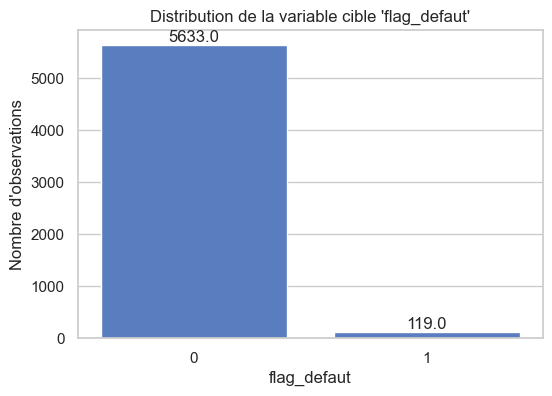

  • Non-défaillants (0): 5633 (97.9%)
  • Défaillants (1): 119 (2.1%)
  • Ratio déséquilibre: 47.3:1


In [36]:
# Création de la variable cible flag_défaut
df['flag_defaut'] = (df['DPD 12M'] > 90).astype(int)
plt.figure(figsize=(6,4))
ax = sns.countplot(x='flag_defaut', data=df)
plt.title("Distribution de la variable cible 'flag_defaut'")
plt.xlabel("flag_defaut")
plt.ylabel("Nombre d'observations")
for p in ax.patches:
    height = p.get_height()
    ax.annotate(f'{height}', 
                (p.get_x() + p.get_width() / 2., height),
                ha='center', va='bottom')

plt.show()
target_dist = df['flag_defaut'].value_counts()
print(f"  • Non-défaillants (0): {target_dist[0]} ({target_dist[0]/len(df)*100:.1f}%)")
print(f"  • Défaillants (1): {target_dist[1]} ({target_dist[1]/len(df)*100:.1f}%)")
print(f"  • Ratio déséquilibre: {target_dist[0]/target_dist[1]:.1f}:1")


ANALYSE UNIVARIÉE - VARIABLES QUANTITATIVES:


Statistiques descriptives:
        Variable    N  Missing Missing %   Moyenne   Médiane       Std        Min         Max Skewness
             CRD 5752        0      0.0% 1,514,236   954,790 2,921,436          0 106,000,000    16.89
             PNU 5752        0      0.0%   187,128         0 1,914,215          0  76,982,379    28.22
    Garantie_max 5752        0      0.0% 1,493,534   900,000 3,780,504          0 215,783,544    34.21
     Solde_moyen 4205     1547     26.9%    74,370    16,477   275,766 -3,043,288   8,215,673    11.65
Revenus_mensuels 3547     2205     38.3%    36,033    27,000    31,986          0     308,897     3.09
      Engagement 5747        5      0.1% 1,677,728 1,006,770 2,823,240          9 106,000,000    13.47
    Age_relation 5752        0      0.0%        47        29        58          0         311     2.46
        Maturite 5752        0      0.0%         4        13        25        -61          25    -2.05
         DPD 12M 5752        0      0.0%     

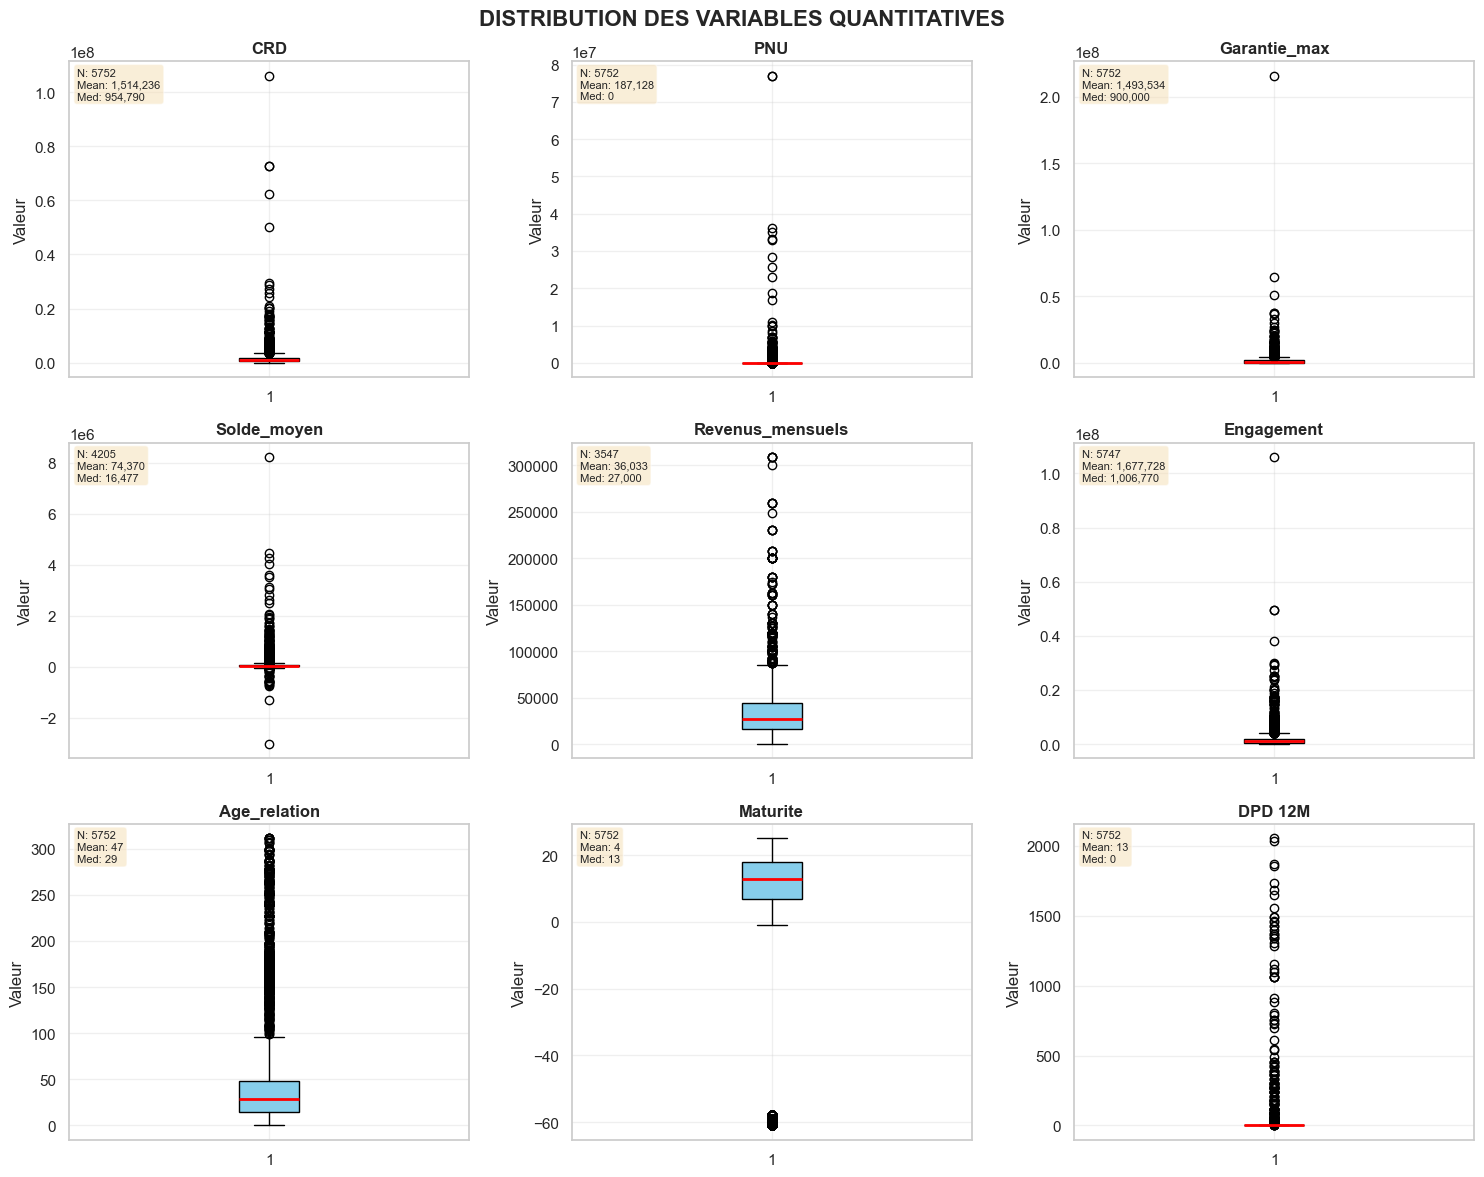

In [37]:
# Variables quantitatives principales
main_quant = ['CRD', 'PNU', 'Garantie_max', 'Solde_moyen', 'Revenus_mensuels', 
              'Engagement', 'Age_relation', 'Maturite', 'DPD 12M']

print("\nStatistiques descriptives:")

stats_summary = []
for var in main_quant:
    if var in df.columns:
        data = df[var].dropna()
        stats = {
            'Variable': var,
            'N': len(data),
            'Missing': df[var].isnull().sum(),
            'Missing %': f"{(df[var].isnull().sum()/len(df)*100):.1f}%",
            'Moyenne': f"{data.mean():,.0f}",
            'Médiane': f"{data.median():,.0f}",
            'Std': f"{data.std():,.0f}",
            'Min': f"{data.min():,.0f}",
            'Max': f"{data.max():,.0f}",
            'Skewness': f"{data.skew():.2f}"
        }
        stats_summary.append(stats)

stats_df = pd.DataFrame(stats_summary)
print(stats_df.to_string(index=False))
print("\n Visualisation des distributions:")

fig_dist, axes = plt.subplots(3, 3, figsize=(15, 12))
fig_dist.suptitle('DISTRIBUTION DES VARIABLES QUANTITATIVES', fontsize=16, fontweight='bold')
axes = axes.ravel()

for idx, var in enumerate(main_quant):
    if var in df.columns:
        ax = axes[idx]
        data = df[var].dropna()
        
        # Boxplot
        ax.boxplot(data, vert=True, patch_artist=True, 
                  boxprops=dict(facecolor='skyblue', color='black'),
                  medianprops=dict(color='red', linewidth=2))
        
        ax.set_title(var, fontweight='bold')
        ax.set_ylabel('Valeur')
        ax.grid(True, alpha=0.3)
        
        # Ajouter statistiques
        stats_text = f"N: {len(data)}\nMean: {data.mean():,.0f}\nMed: {data.median():,.0f}"
        ax.text(0.02, 0.98, stats_text, transform=ax.transAxes,
                fontsize=8, verticalalignment='top',
                bbox=dict(boxstyle='round', facecolor='wheat', alpha=0.5))

plt.tight_layout()
plt.show()


 ANALYSE UNIVARIÉE - VARIABLES QUALITATIVES:

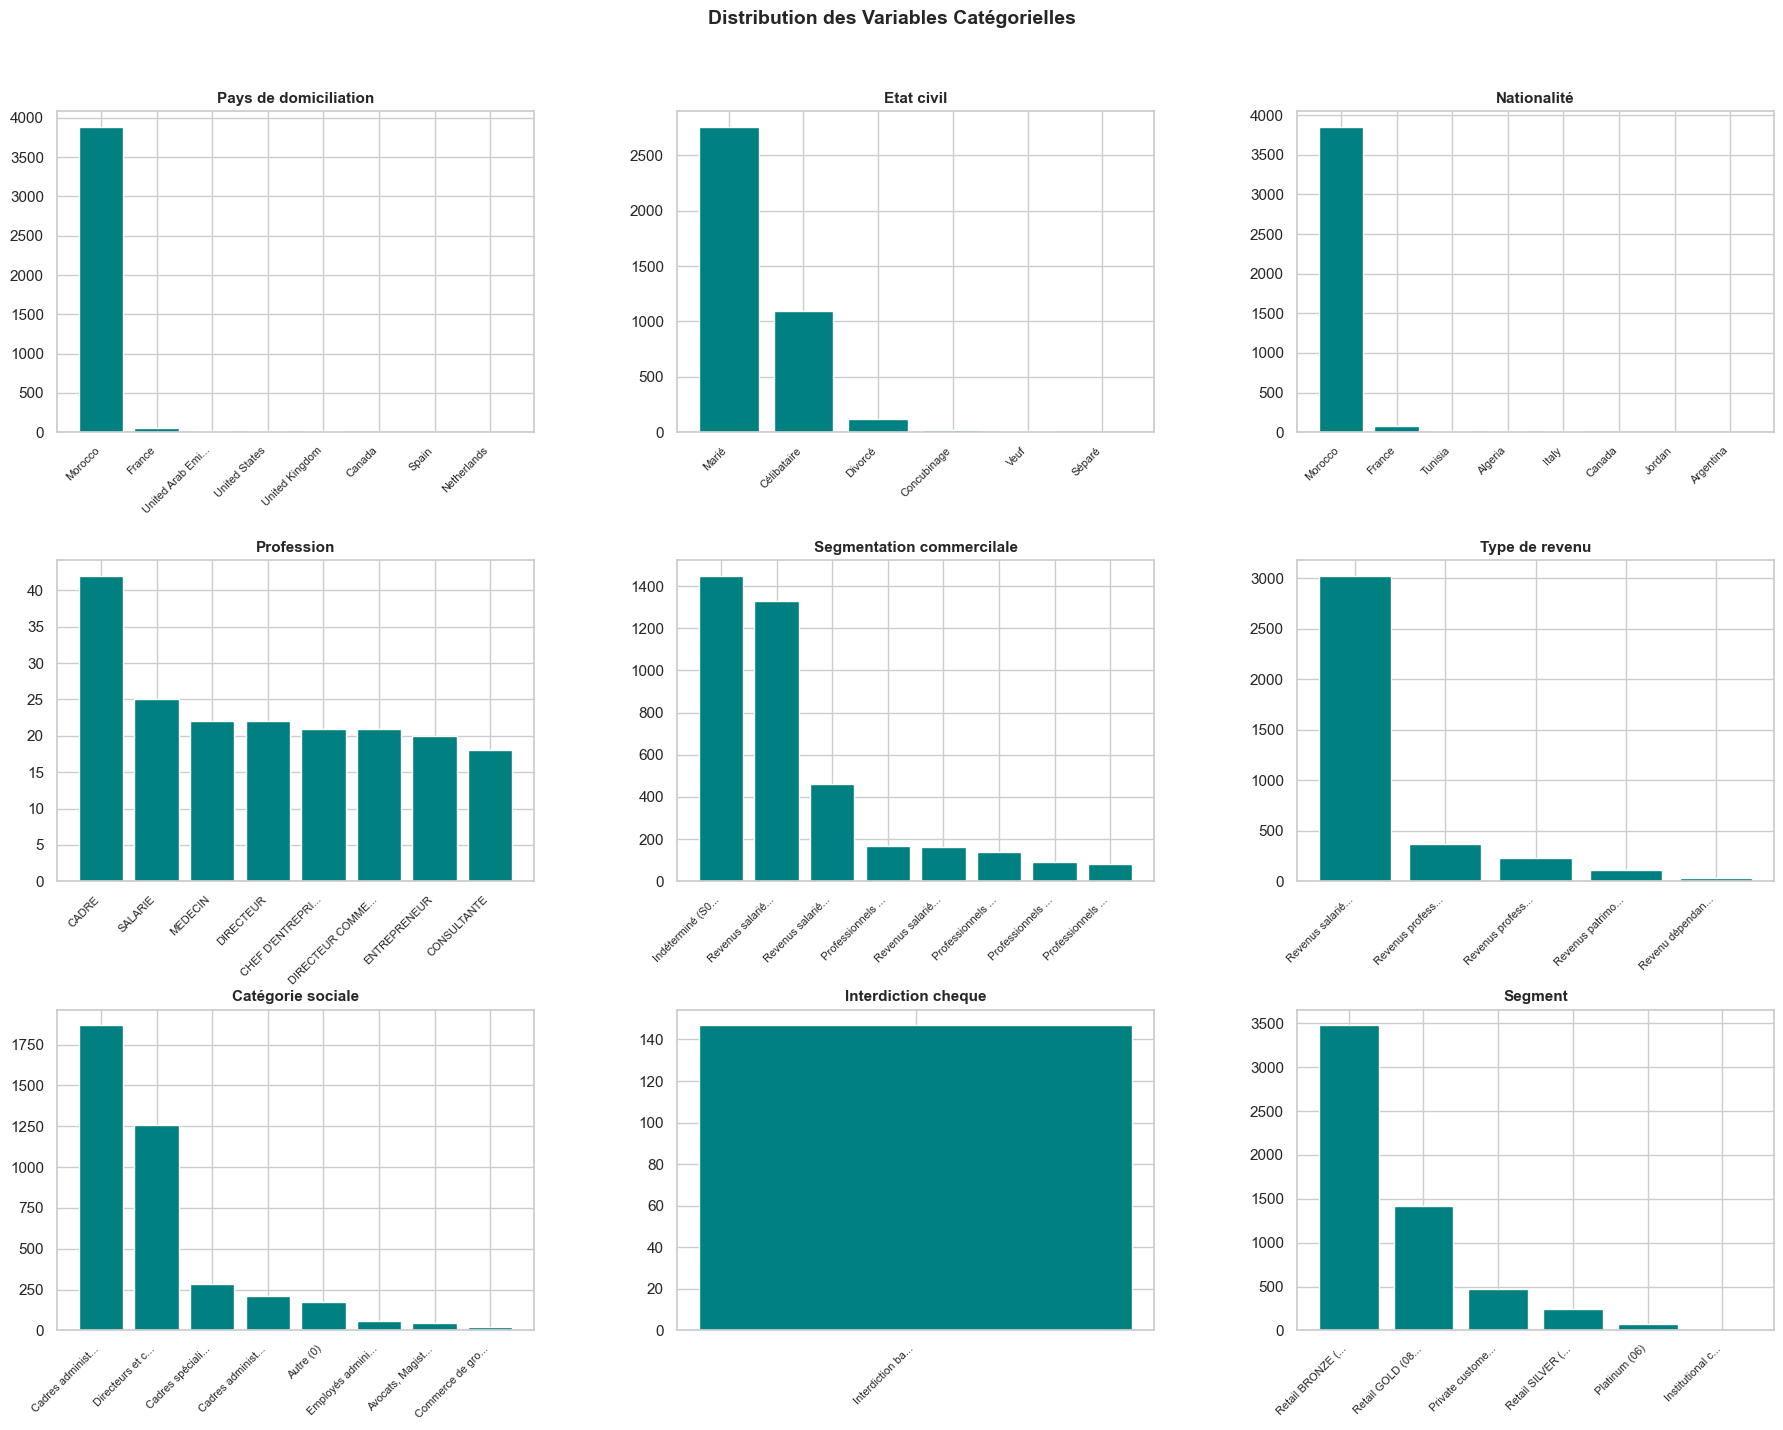

In [38]:

main_cat = ['Pays de domiciliation', 'Etat civil', 'Nationalité', 'Profession', 
                  'Segmentation commercilale', 'Type de revenu', 'Catégorie sociale', 
                  'Interdiction cheque', 'Segment']
print("\n Fréquences des catégories:")

for var in main_cat: 
    if var in df.columns:
        print(f"\n{var}:")
        freq = df[var].value_counts(dropna=False)
        for val, count in freq.items():
            pct = count/len(df)*100
            print(f"  {val}: {count} ({pct:.1f}%)")


print("\n Visualisation des distributions catégorielles:")

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()

for idx, var in enumerate(main_cat):
    if var in df.columns and idx < len(axes):
        ax = axes[idx]
        freq = df[var].value_counts().head(8)  
        labels = [str(x)[:15] + '...' if len(str(x)) > 15 else str(x) for x in freq.index]
        bars = ax.bar(range(len(freq)), freq.values, color='teal', edgecolor='white')
        ax.set_xticks(range(len(freq)))
        ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
        
        ax.set_title(f'{var}', fontsize=11, fontweight='bold')
        ax.set_xlabel('')

plt.suptitle('Distribution des Variables Catégorielles', fontsize=14, fontweight='bold', y=1.02)
plt.tight_layout()
plt.subplots_adjust(hspace=0.4, wspace=0.3)
plt.show()

ANALYSE BIVARIÉE :

 ANALYSE BIVARIÉE - VARIABLES QUANTI/QUANTI


 Matrice de corrélation (variables financières principales):


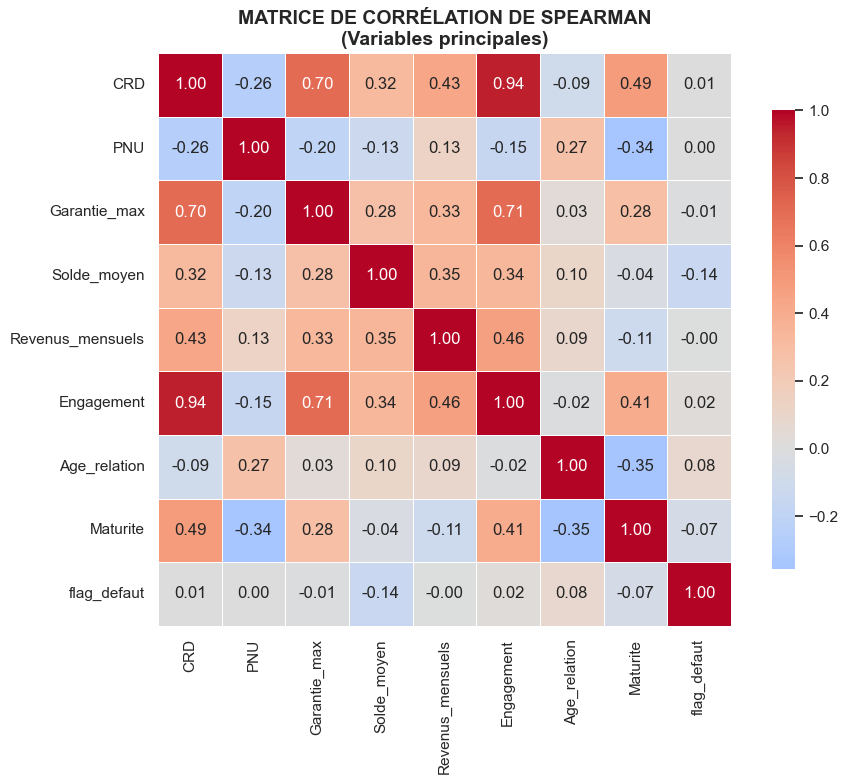


Corrélations fortes (|r| > 0.7):
  • CRD - Garantie_max: 0.704
  • CRD - Engagement: 0.944
  • Garantie_max - Engagement: 0.708

Corrélation avec la variable cible:
  • Solde_moyen: -0.138 *
  • Age_relation: 0.080 
  • Maturite: -0.067 
  • Engagement: 0.018 
  • Garantie_max: -0.008 
  • CRD: 0.007 
  • PNU: 0.002 
  • Revenus_mensuels: -0.001 


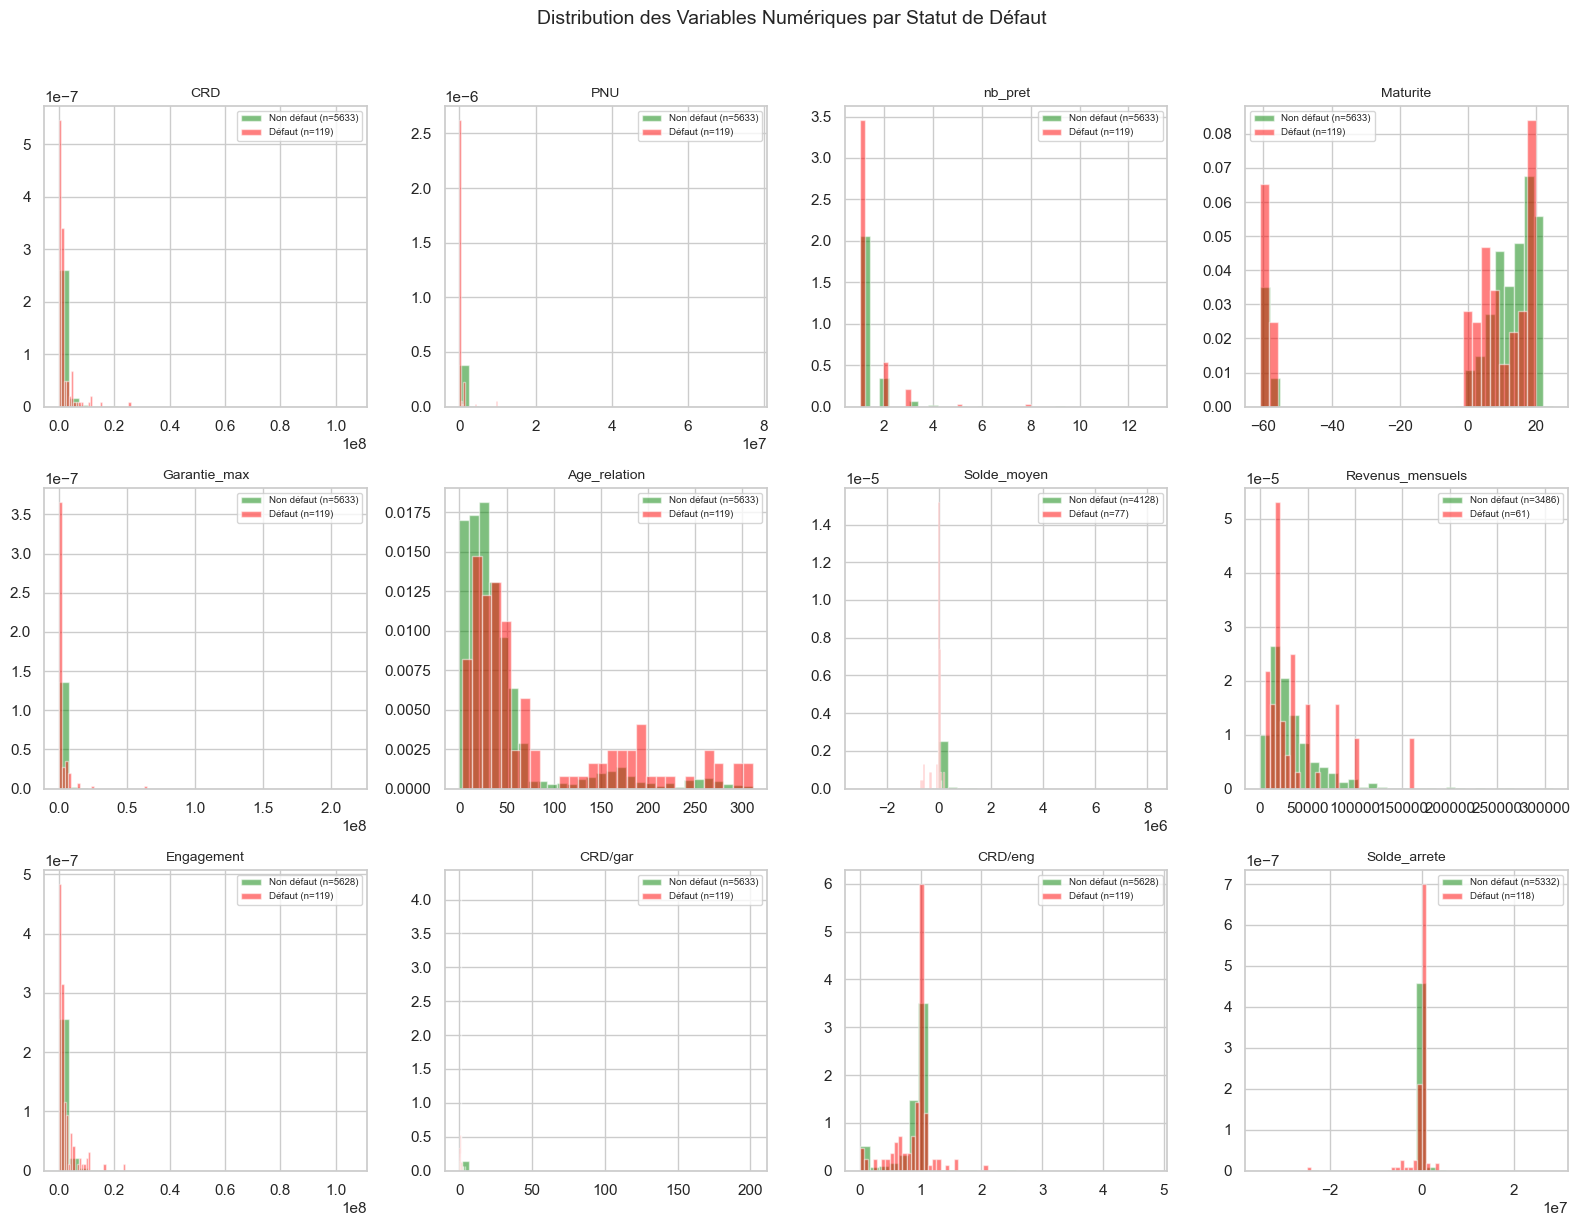

In [39]:

print("\n Matrice de corrélation (variables financières principales):")

# Sélection des variables pour corrélation
corr_vars = main_quant[:-1] + ['flag_defaut']
corr_data = df[corr_vars].corr(method='spearman')

plt.figure(figsize=(10, 8))
sns.heatmap(corr_data, annot=True, cmap='coolwarm', center=0, 
            square=True, linewidths=0.5, fmt='.2f',
            cbar_kws={"shrink": 0.8})
plt.title('MATRICE DE CORRÉLATION DE SPEARMAN\n(Variables principales)', 
         fontsize=14, fontweight='bold')
plt.tight_layout()
plt.show()

print("\nCorrélations fortes (|r| > 0.7):")
for i in range(len(corr_vars)):
    for j in range(i+1, len(corr_vars)):
        corr_val = corr_data.iloc[i, j]
        if abs(corr_val) > 0.7:
            print(f"  • {corr_vars[i]} - {corr_vars[j]}: {corr_val:.3f}")

print("\nCorrélation avec la variable cible:")
corr_target = corr_data['flag_defaut'].sort_values(key=abs, ascending=False)
for var, corr in corr_target.items():
    if var != 'flag_defaut':
        significance = "***" if abs(corr) > 0.3 else "**" if abs(corr) > 0.2 else "*" if abs(corr) > 0.1 else ""
        print(f"  • {var}: {corr:.3f} {significance}")

# %%
fig, axes = plt.subplots(3, 4, figsize=(16, 12))
axes = axes.flatten()

# Variables à comparer
vars_num_analyse = ['CRD', 'PNU', 'nb_pret', 'Maturite', 'Garantie_max', 'Age_relation', 
                    'Solde_moyen', 'Revenus_mensuels', 'Engagement', 'CRD/gar', 'CRD/eng', 'Solde_arrete']

for i, var in enumerate(vars_num_analyse):
    if var in df.columns and i < len(axes):
        ax = axes[i]
        # Comparaison des distributions entre défaut et non défaut
        df_0 = df[df['flag_defaut'] == 0][var].dropna()
        df_1 = df[df['flag_defaut'] == 1][var].dropna()
        
        ax.hist(df_0, bins=30, alpha=0.5, label=f'Non défaut (n={len(df_0)})', color='green', density=True)
        ax.hist(df_1, bins=30, alpha=0.5, label=f'Défaut (n={len(df_1)})', color='red', density=True)
        ax.set_title(f'{var}', fontsize=10)
        ax.legend(fontsize=7)

plt.suptitle('Distribution des Variables Numériques par Statut de Défaut', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()





ANALYSE BIVARIÉE - VARIABLES QUALI/QUANTI (ANOVA)


Impact des variables catégorielles sur la variable cible:

Force d'association avec la variable cible (Cramér's V):
                 Variable  Cramér's V   Force  Catégories
        Catégorie sociale    0.163304 MODÉRÉE          18
Segmentation commercilale    0.158558 MODÉRÉE          16
      Interdiction cheque    0.150042 MODÉRÉE           1
                  Segment    0.112067 MODÉRÉE           6
           Type de revenu    0.100952 MODÉRÉE           5
    Pays de domiciliation    0.056361  FAIBLE          14
               Etat civil    0.029298  FAIBLE           6
              Nationalité    0.000000  FAIBLE          14


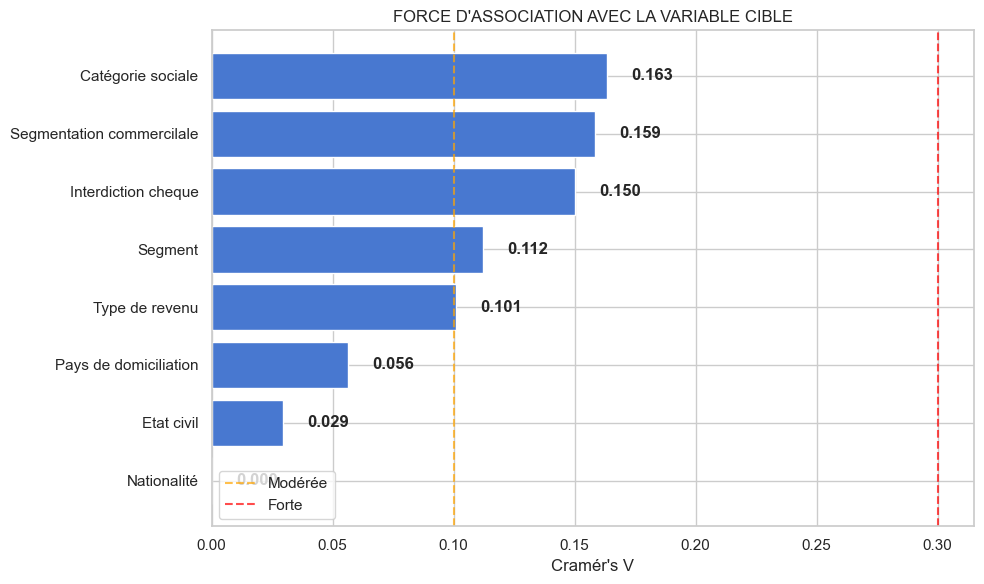


 Taux de défaut par catégorie:


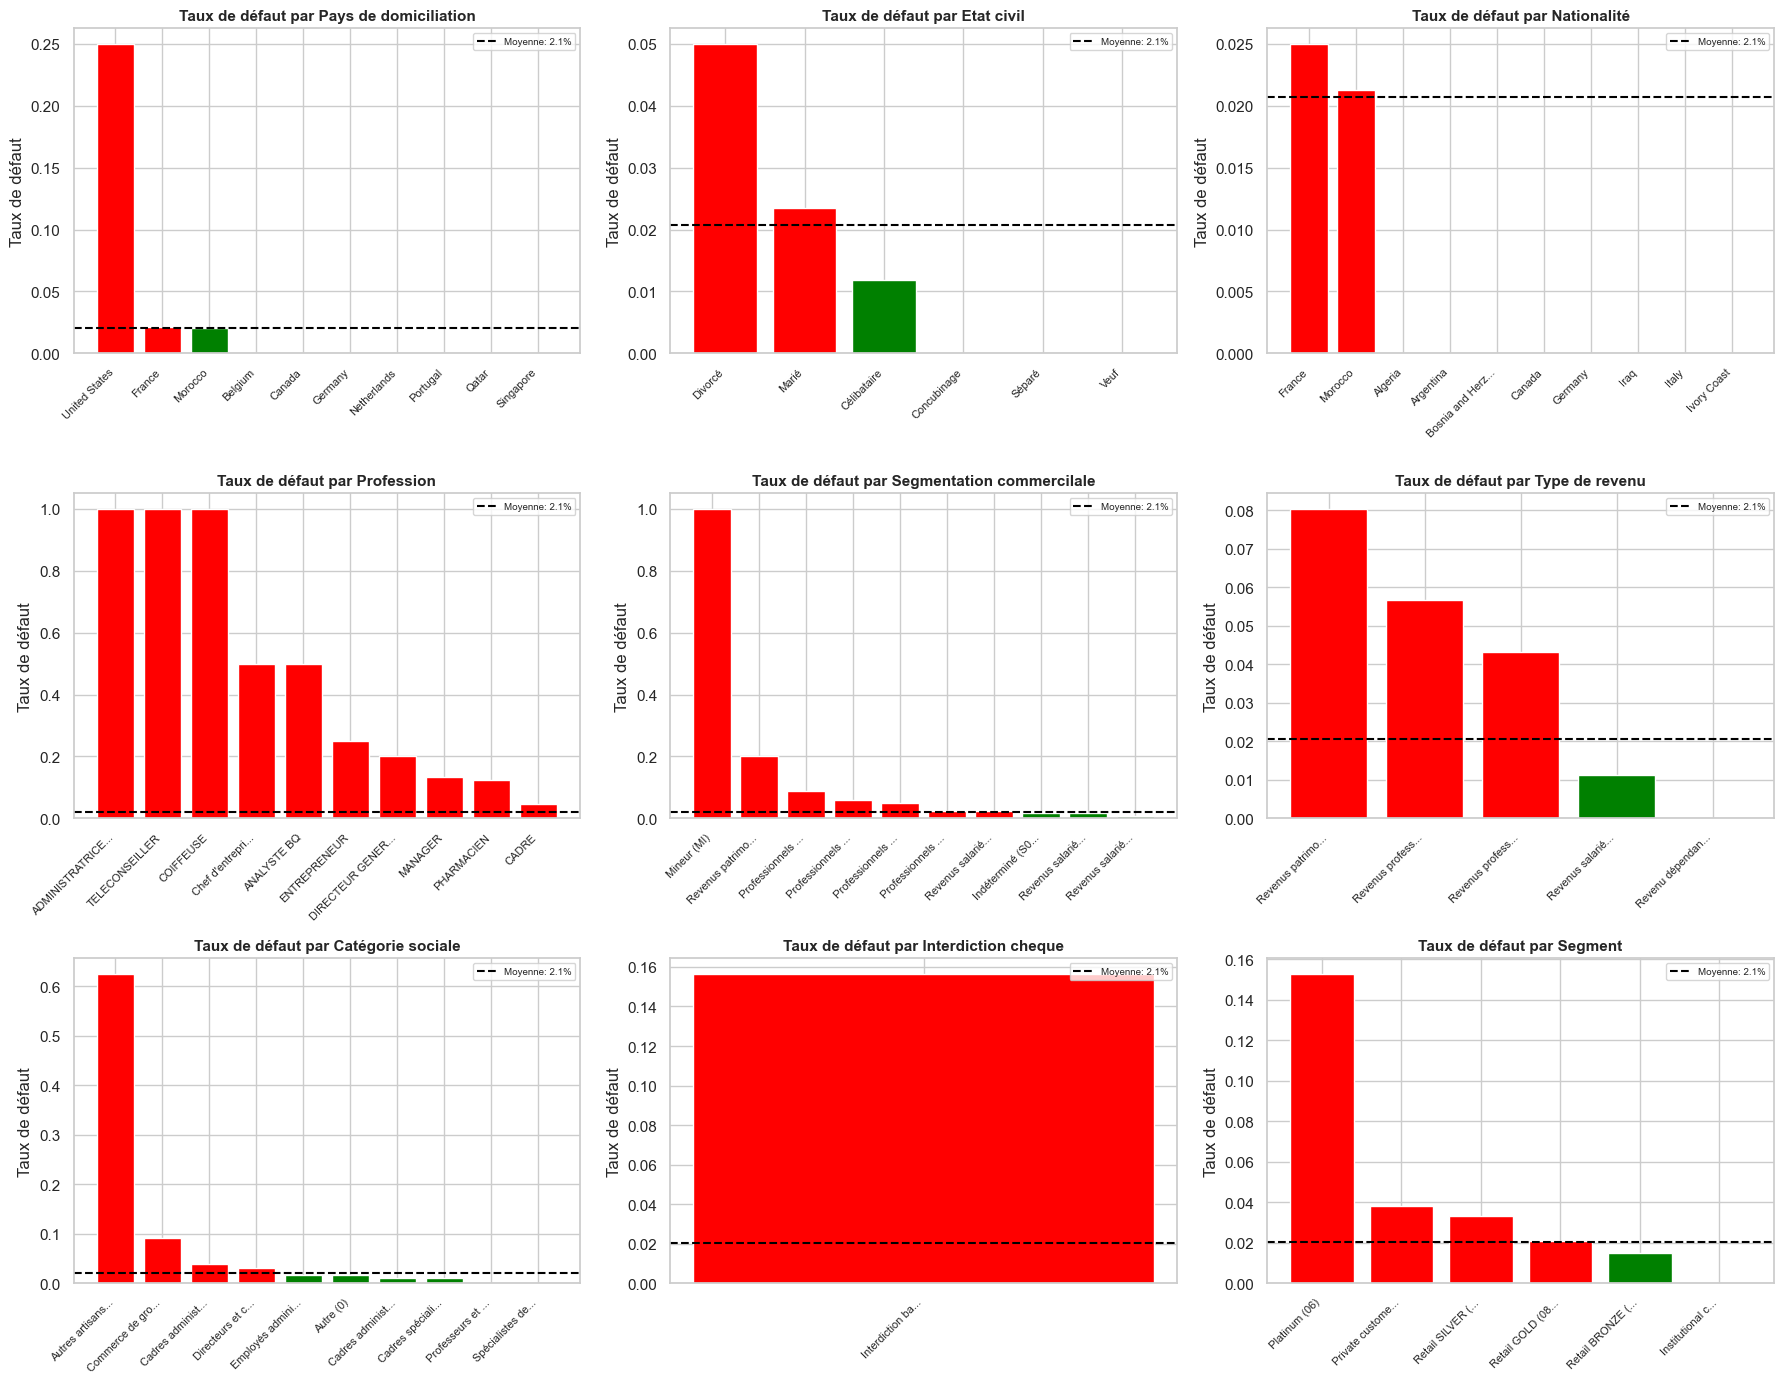

In [40]:
print("\nImpact des variables catégorielles sur la variable cible:")

# Fonction pour calculer Cramér's V
def cramers_v(x, y):
    confusion_matrix = pd.crosstab(x, y)
    chi2 = chi2_contingency(confusion_matrix)[0]
    n = confusion_matrix.sum().sum()
    phi2 = chi2 / n
    r, k = confusion_matrix.shape
    phi2corr = max(0, phi2 - ((k-1)*(r-1))/(n-1))
    rcorr = r - ((r-1)**2)/(n-1)
    kcorr = k - ((k-1)**2)/(n-1)
    return np.sqrt(phi2corr / min((kcorr-1), (rcorr-1)))

# Analyse des principales variables catégorielles
print("\nForce d'association avec la variable cible (Cramér's V):")

cramer_results = []
for cat_var in main_cat: 
    if cat_var in df.columns and df[cat_var].nunique() < 20:
        # Gérer les NaN
        temp_var = df[cat_var].fillna('Missing')
        v_stat = cramers_v(temp_var, df['flag_defaut'])
        
        # Interprétation
        if v_stat > 0.3:
            strength = 'FORTE'
        elif v_stat > 0.1:
            strength = 'MODÉRÉE'
        else:
            strength = 'FAIBLE'
        
        cramer_results.append({
            'Variable': cat_var,
            "Cramér's V": v_stat,
            'Force': strength,
            'Catégories': df[cat_var].nunique()
        })

cramer_df = pd.DataFrame(cramer_results).sort_values("Cramér's V", ascending=False)
print(cramer_df.to_string(index=False))

# Visualisation
if len(cramer_df) > 0:
    plt.figure(figsize=(10, 6))
    bars = plt.barh(cramer_df['Variable'], cramer_df["Cramér's V"])
    plt.xlabel("Cramér's V")
    plt.title('FORCE D\'ASSOCIATION AVEC LA VARIABLE CIBLE')
    plt.gca().invert_yaxis()
    
    # Lignes de référence
    plt.axvline(x=0.1, color='orange', linestyle='--', alpha=0.7, label='Modérée')
    plt.axvline(x=0.3, color='red', linestyle='--', alpha=0.7, label='Forte')
    
    for bar, v in zip(bars, cramer_df["Cramér's V"]):
        plt.text(bar.get_width() + 0.01, bar.get_y() + bar.get_height()/2,
                f'{v:.3f}', va='center', fontweight='bold')
    
    plt.legend()
    plt.tight_layout()
    plt.show()

# %%
print("\n Taux de défaut par catégorie:")

fig, axes = plt.subplots(3, 3, figsize=(18, 14))
axes = axes.flatten()



for idx, var in enumerate(main_cat):
    if var in df.columns:
        ax = axes[idx]
        
        # Calculer le taux de défaut par modalité
        taux_defaut = df.groupby(var)['flag_defaut'].mean().sort_values(ascending=False).head(10)
        colors = ['red' if x > df['flag_defaut'].mean() else 'green' for x in taux_defaut]
        # Tronquer les labels longs
        labels = [str(x)[:15] + '...' if len(str(x)) > 15 else str(x) for x in taux_defaut.index]
        bars = ax.bar(range(len(taux_defaut)), taux_defaut.values, color=colors, edgecolor='white')
        ax.set_xticks(range(len(taux_defaut)))
        ax.set_xticklabels(labels, rotation=45, ha='right', fontsize=8)
        ax.axhline(y=df['flag_defaut'].mean(), color='black', linestyle='--', label=f"Moyenne: {df['flag_defaut'].mean()*100:.1f}%")
        ax.set_title(f'Taux de défaut par {var}', fontsize=11, fontweight='bold')
        ax.set_ylabel('Taux de défaut')
        ax.legend(fontsize=7)

plt.tight_layout()
plt.show()



3.Qualité des Données (Doublons & Valeurs Manquantes):

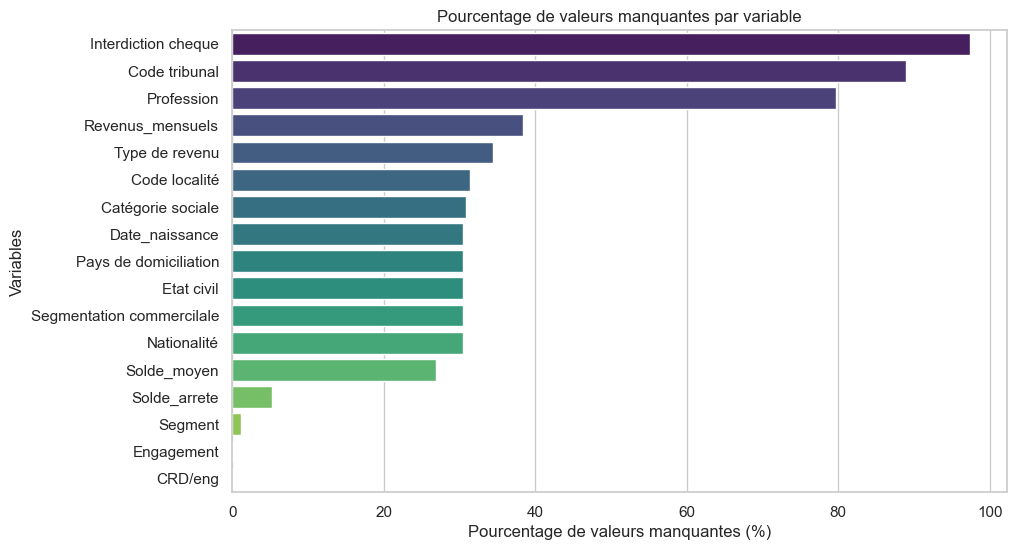

In [41]:


#  Analyse des valeurs manquantes
missing_data = pd.DataFrame({
    'Variable': df.columns,
    'Valeurs_manquantes': df.isnull().sum(),
    'Pourcentage': (df.isnull().sum() / len(df) * 100),
    'Type': df.dtypes.values
})
missing_data = missing_data[missing_data['Valeurs_manquantes'] > 0]
missing_data = missing_data.sort_values(by='Pourcentage', ascending=False)
print("\n=== ANALYSE DES VALEURS MANQUANTES ===\n")
print(f"Total de variables: {len(df.columns)}")
print(f"Variables avec valeurs manquantes: {(missing_data['Valeurs_manquantes'] > 0).sum()}")
print(missing_data.to_string(index=False))
plt.figure(figsize=(10,6))
sns.barplot(x='Pourcentage', y='Variable', data=missing_data, palette='viridis')
plt.title("Pourcentage de valeurs manquantes par variable")
plt.xlabel("Pourcentage de valeurs manquantes (%)")
plt.ylabel("Variables")
plt.show()




In [42]:
# Vérifier les doublons complets
duplicates = df.duplicated()
n_duplicates = duplicates.sum()
print(f"Doublons complets: {n_duplicates} ({n_duplicates/len(df)*100:.1f}%)")

# Vérifier les doublons sur des identifiants clés
if 'id_tiers' in df.columns:
    duplicates_id = df.duplicated(subset=['id_tiers'], keep=False)
    n_duplicates_id = duplicates_id.sum()
    if n_duplicates_id > 0:
        print(f"Doublons sur id_tiers: {n_duplicates_id} observations")
        print("Exemples de doublons:")
        print(df[duplicates_id]['id_tiers'].value_counts().head())

if 'code_client' in df.columns:
    duplicates_code = df.duplicated(subset=['code_client'], keep=False)
    n_duplicates_code = duplicates_code.sum()
    if n_duplicates_code > 0:
        print(f"Doublons sur code_client: {n_duplicates_code} observations")




4.Analyse des incohérences (valeurs aberrantes et anomalies métier)


Analyse des valeurs aberrantes (outliers)

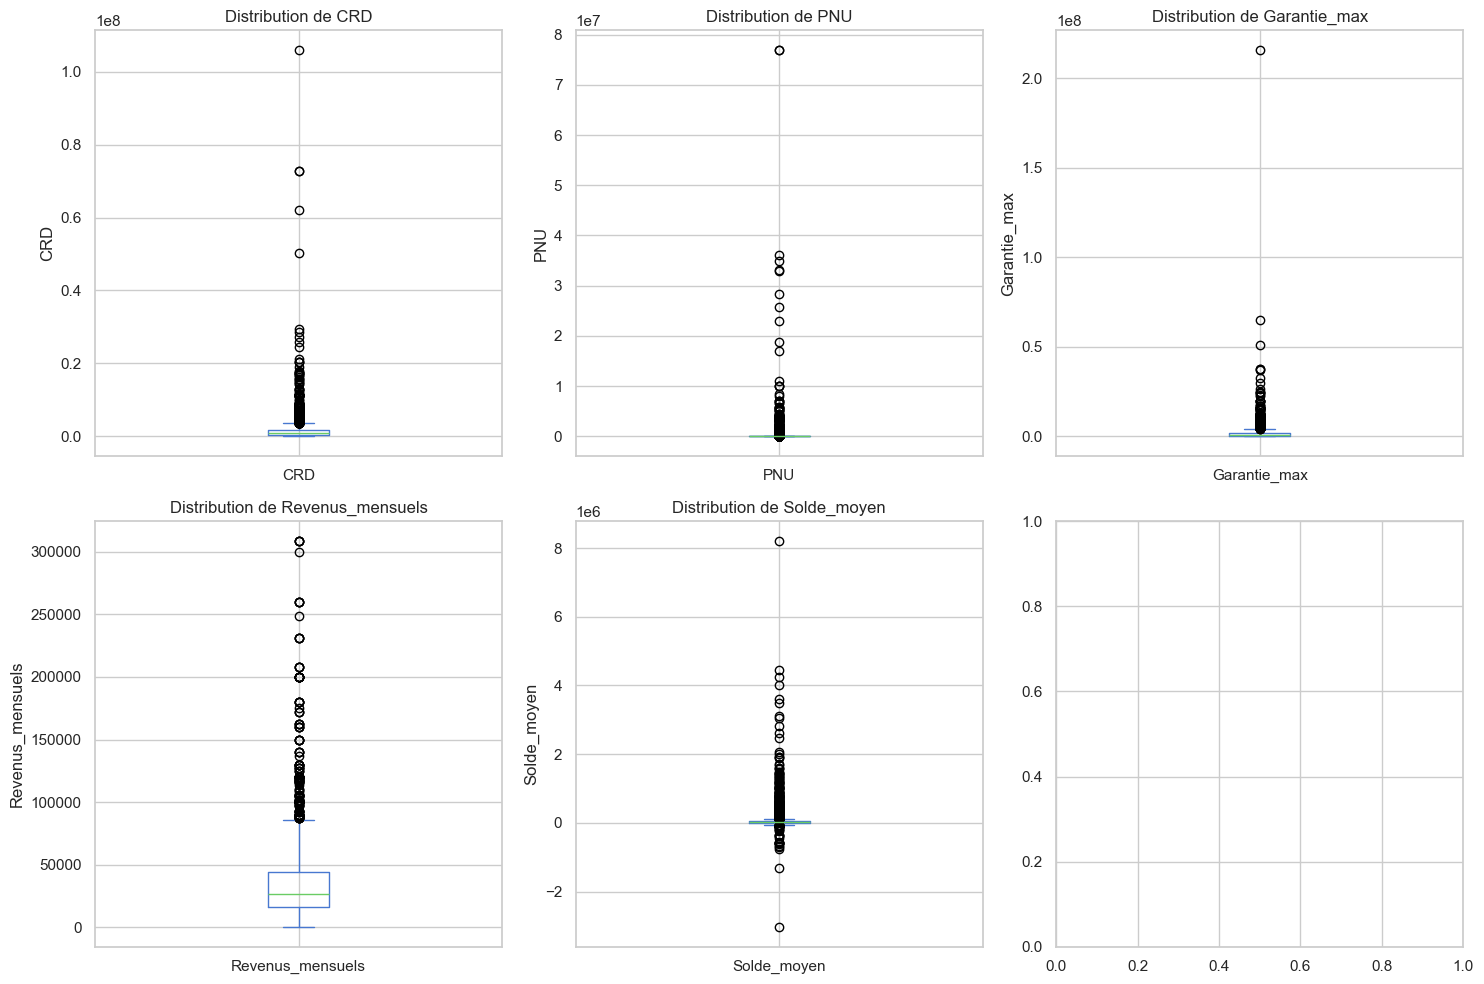

In [43]:
print("\n=== ANALYSE DES VALEURS ABERRANTES ===\n")

# Définir les variables numériques à analyser
numeric_vars = continues + discretes

# Fonction pour détecter les outliers avec méthode IQR
def detect_outliers_iqr(data, variable):
    Q1 = data[variable].quantile(0.25)
    Q3 = data[variable].quantile(0.75)
    IQR = Q3 - Q1
    lower_bound = Q1 - 1.5 * IQR
    upper_bound = Q3 + 1.5 * IQR
    
    outliers = data[(data[variable] < lower_bound) | (data[variable] > upper_bound)]
    return outliers, lower_bound, upper_bound

# Analyser les outliers pour chaque variable numérique
outliers_summary = []
for var in numeric_vars:
    try:
        outliers, lower, upper = detect_outliers_iqr(df, var)
        n_outliers = len(outliers)
        percentage = (n_outliers / len(df)) * 100
        
        if n_outliers > 0:
            outliers_summary.append({
                'Variable': var,
                'Outliers': n_outliers,
                'Pourcentage': f"{percentage:.1f}%",
                'Min_val': df[var].min(),
                'Max_val': df[var].max(),
                'Lower_bound': lower,
                'Upper_bound': upper
            })
    except:
        continue

# Créer un DataFrame avec le résumé
if outliers_summary:
    outliers_df = pd.DataFrame(outliers_summary)
    print("Variables avec valeurs aberrantes (méthode IQR) :")
    print(outliers_df.to_string(index=False))
    
    # Visualisation des outliers pour quelques variables importantes
    important_vars = ['CRD', 'PNU', 'Garantie_max', 'Revenus_mensuels', 'Solde_moyen']
    
    fig, axes = plt.subplots(2, 3, figsize=(15, 10))
    axes = axes.flatten()
    
    for i, var in enumerate(important_vars):
        if var in df.columns:
            ax = axes[i]
            df[var].plot(kind='box', ax=ax)
            ax.set_title(f'Distribution de {var}')
            ax.set_ylabel(var)
    
    plt.tight_layout()
    plt.show()
else:
    print("Aucune valeur aberrante détectée avec la méthode IQR.")

 Analyse des incohérences logiques:

In [44]:
# 1. Incohérences entre variables liées
incoherences = []

# CRD ne peut pas être négatif
if (df['CRD'] < 0).any():
    n_neg = (df['CRD'] < 0).sum()
    incoherences.append(f"CRD négatif: {n_neg} observations ({n_neg/len(df)*100:.1f}%)")

# PNU ne peut pas être négatif
if (df['PNU'] < 0).any():
    n_neg = (df['PNU'] < 0).sum()
    incoherences.append(f"PNU négatif: {n_neg} observations")
#maturité ne peut pas être négative
if (df['Maturite'] < 0).any():
    n_neg = (df['Maturite'] < 0).sum()
    incoherences.append(f"Maturite négative: {n_neg} observations")
#garantie_max ne peut pas être négative
if (df['Garantie_max'] < 0).any():
    n_neg = (df['Garantie_max'] < 0).sum()
    incoherences.append(f"Garantie_max négative: {n_neg} observations")
#revenus_mensuels ne peut pas être négatif
if (df['Revenus_mensuels'] < 0).any():
    n_neg = (df['Revenus_mensuels'] < 0).sum()
    incoherences.append(f"Revenus_mensuels négatif: {n_neg} observations")
#nb_pret ne peut pas être négatif
if (df['nb_pret'] < 0).any():
    n_neg = (df['nb_pret'] < 0).sum()
    incoherences.append(f"nb_pret négatif: {n_neg} observations")
#verifier DPD 12M:
if (df['DPD 12M'] < 0).any():
    n_neg = (df['DPD 12M'] < 0).sum()
    incoherences.append(f"DPD 12M négatif: {n_neg} observations")


# Vérifier les ratios CRD/gar et CRD/eng
if 'CRD/gar' in df.columns:
    # CRD/gar devrait être <= 1 (sauf exceptions)
    inc_coherent = (df['CRD/gar'] <= 1) | (df['CRD/gar'].isnull())
    n_incoherent = (~inc_coherent).sum()
    if n_incoherent > 0:
        incoherences.append(f"CRD/gar > 1: {n_incoherent} observations")

if 'CRD/eng' in df.columns:
    # CRD/eng devrait être <= 1
    inc_coherent = (df['CRD/eng'] <= 1) | (df['CRD/eng'].isnull())
    n_incoherent = (~inc_coherent).sum()
    if n_incoherent > 0:
        incoherences.append(f"CRD/eng > 1: {n_incoherent} observations")

# Vérifier les âges cohérents
if 'Date_naissance' in df.columns and 'date OBSERVATION' in df.columns:
    # Calculer l'âge à la date d'observation
    df['Age_calculé'] = (df['date OBSERVATION'] - df['Date_naissance']).dt.days / 365.25
    
    # Vérifier les âges plausibles (entre 18 et 100 ans)
    age_plausible = (df['Age_calculé'] >= 18) & (df['Age_calculé'] <= 100)
    n_age_incoherent = (~age_plausible).sum()
    if n_age_incoherent > 0:
        incoherences.append(f"Âge incohérent (hors 18-100 ans): {n_age_incoherent} observations")
elif 'Date_naissance' in df.columns :
    df['Age_calculé'] = (pd.to_datetime('today') - df['Date_naissance']).dt.days / 365.25
    age_plausible = (df['Age_calculé'] >= 18) & (df['Age_calculé'] <= 100)
    n_age_incoherent = (~age_plausible).sum()
    if n_age_incoherent > 0:
        incoherences.append(f"Âge incohérent (hors 18-100 ans): {n_age_incoherent} observations")
   
if incoherences:
    print("Incohérences logiques détectées:")
    for inc in incoherences:
        print(f"  • {inc}")
else:
    print("Aucune incohérence logique majeure détectée.")

Incohérences logiques détectées:
  • Maturite négative: 733 observations
  • CRD/gar > 1: 747 observations
  • CRD/eng > 1: 508 observations
  • Âge incohérent (hors 18-100 ans): 1759 observations


 Analyse des distributions et validations

In [45]:
print("\n=== VALIDATION DES DISTRIBUTIONS ===\n")

# Vérifier les distributions pour les variables catégorielles
for var in qualitatives:
    unique_values = df[var].nunique()
    if unique_values < 20:  # Afficher seulement pour variables avec peu de modalités
        print(f"\n{var}:")
        print(f"  Nombre de modalités: {unique_values}")
        print(f"  Distribution:")
        print(df[var].value_counts(dropna=False).head(10))
        
        # Détecter les modalités rares
        value_counts = df[var].value_counts(normalize=True)
        rare_categories = value_counts[value_counts < 0.01].index.tolist()
        if rare_categories:
            print(f"  Modalités rares (<1%): {len(rare_categories)}")

# Vérifier les plages de valeurs pour les variables numériques
print("\nPlages de valeurs pour variables clés:")
key_vars = ['CRD', 'PNU', 'Garantie_max', 'Revenus_mensuels', 'Solde_moyen', 'Age_relation']
for var in key_vars:
    if var in df.columns:
        print(f"\n{var}:")
        print(f"  Min: {df[var].min():,.0f}")
        print(f"  Max: {df[var].max():,.0f}")
        print(f"  Médiane: {df[var].median():,.0f}")
        print(f"  Moyenne: {df[var].mean():,.0f}")

5. Synthèse des problèmes de qualité:

In [46]:
print("\n" + "="*80)
print(" STRATÉGIE DE TRAITEMENT PROPOSÉE")
print("="*80)

print("\nVariables à exclure:")
print("   • Variables avec >50% valeurs manquantes")
if len(missing_data) > 0:
    for var in missing_data['Variable'].head(3):  # Afficher les 3 premières
        taux = missing_data[missing_data['Variable'] == var]['Pourcentage'].iloc[0]
        print(f"     - {var} ({taux:.1f}% manquants)")

print("\nVariables à imputer:")
print("   • Variables avec <50% valeurs manquantes → médiane/mode")
print("   • Revenus_mensuels négatifs → médiane")

print("\nVariables à corriger:")
print("   • DPD 12M négatif → exclure observations")
print("   • Age_relation négatif → corriger à 0")
print("   • CRD/gar > 1 → cap à 1")

# ETAPE 2 : TRAITEMENT DES DONNEES & PREPARATION:

In [47]:
#Création d'une copie de sécurité:
df_cl = df.copy()

1. Traitement des doublons: 

In [48]:
#suppression des doublons exacts
initial_count = len(df_cl)
df_cl = df_cl.drop_duplicates()
final_count = len(df_cl)
n_removed = initial_count - final_count
print(f"\nSuppression des doublons exacts: {n_removed} observations supprimées.")
print(f"Nombre d'observations après suppression des doublons: {final_count}")
# Pour les doublons sur id_tiers, garder la dernière observation
if 'id_tiers' in df_cl.columns:
    initial_count = len(df_cl)
    df_cl = df_cl.sort_values(by='date OBSERVATION').drop_duplicates(subset=['id_tiers'], keep='last')
    final_count = len(df_cl)
    n_removed = initial_count - final_count
    print(f"Suppression des doublons sur id_tiers: {n_removed} observations supprimées.")
    print(f"Nombre d'observations après suppression des doublons sur id_tiers: {final_count}")

    


2.Traitements des variables manquantes:

In [49]:
low_missing_vars = missing_data[missing_data['Pourcentage'] < 50]['Variable'].tolist()
high_missing_vars = missing_data[missing_data['Pourcentage'] >= 50]['Variable'].tolist()
print(f"\nVariables avec <50% valeurs manquantes: {len(low_missing_vars)}")
print(f"Variables avec >=50% valeurs manquantes: {len(high_missing_vars)}")
cols_high_missing = [c for c in high_missing_vars if c in df_cl.columns]
df_cl = df_cl.drop(columns=cols_high_missing)
#Imputation des variables avec peu de valeurs manquantes (<50%)
quant_vars = df_cl.select_dtypes(include=[np.number]).columns.tolist()
cat_vars = df_cl.select_dtypes(include=['object']).columns.tolist()
# Imputation pour variables numériques (médiane)
num_imputer = SimpleImputer(strategy='median')
df_cl[quant_vars] = num_imputer.fit_transform(df_cl[quant_vars])

# Imputation pour variables catégorielles (mode)
cat_imputer = SimpleImputer(strategy='most_frequent')
df_cl[cat_vars] = cat_imputer.fit_transform(df_cl[cat_vars])
print("\nVérification après imputation:")
print(f"   Valeurs manquantes restantes: {df_cl.isnull().sum().sum()}")




Variables avec <50% valeurs manquantes: 14
Variables avec >=50% valeurs manquantes: 3

Vérification après imputation:
   Valeurs manquantes restantes: 1749


3. Traitements des incoherences :


In [50]:
# 1. Maturite negative -> Remplacer par 0 (pret echu)
if 'Maturite' in df_cl.columns:
    neg_maturite = (df_cl['Maturite'] < 0).sum()
    df_cl.loc[df_cl['Maturite'] < 0, 'Maturite'] = 0
    print(f"Maturite negative: {neg_maturite} valeurs -> remplacees par 0")
# 2. Traitement de la date de naissance 
# Utiliser date OBSERVATION - Date_naissance pour un calcul correct
if 'Date_naissance' in df_cl.columns and 'date OBSERVATION' in df.columns:
    # Recuperer la date d'observation depuis le df original (aligne sur l'index)
    date_obs = df.loc[df_cl.index, 'date OBSERVATION']
    df_cl['Age'] = (date_obs - df_cl['Date_naissance']).dt.days / 365.25
    # Borner les ages aberrants
    df_cl.loc[df_cl['Age'] < 18, 'Age'] = 18
    df_cl.loc[df_cl['Age'] > 100, 'Age'] = df_cl['Age'].median()
    # Supprimer la colonne date
    df_cl = df_cl.drop(columns=['Date_naissance'])
    print("Date_naissance -> convertie en 'Age' (date OBSERVATION - Date_naissance, borne 18-100)")
elif 'Date_naissance' in df_cl.columns:
    # Fallback si date OBSERVATION n'est pas disponible
    df_cl['Age'] = (pd.Timestamp.now() - df_cl['Date_naissance']).dt.days / 365.25
    df_cl.loc[df_cl['Age'] < 18, 'Age'] = 18
    df_cl.loc[df_cl['Age'] > 100, 'Age'] = df_cl['Age'].median()
    df_cl = df_cl.drop(columns=['Date_naissance'])
    print("Date_naissance -> convertie en 'Age' (fallback: date actuelle, borne 18-100)")
# 3. Verifier et borner les ratios aberrants
if 'CRD/gar' in df_cl.columns:
    q99 = df_cl['CRD/gar'].quantile(0.99)
    outliers_crd_gar = (df_cl['CRD/gar'] > q99).sum()
    df_cl.loc[df_cl['CRD/gar'] > q99, 'CRD/gar'] = q99
    print(f"CRD/gar: {outliers_crd_gar} outliers bornes au 99e percentile ({q99:.2f})")
if 'CRD/eng' in df_cl.columns:
    q99 = df_cl['CRD/eng'].quantile(0.99)
    outliers_crd_eng = (df_cl['CRD/eng'] > q99).sum()
    df_cl.loc[df_cl['CRD/eng'] > q99, 'CRD/eng'] = q99
    print(f"CRD/eng: {outliers_crd_eng} outliers bornes au 99e percentile ({q99:.2f})")

#traitement des outliers avec winsorization
for var in numeric_vars:
    try:
        lower_percentile = df_cl[var].quantile(0.01)
        upper_percentile = df_cl[var].quantile(0.99)
        n_below = (df_cl[var] < lower_percentile).sum()
        n_above = (df_cl[var] > upper_percentile).sum()
        df_cl.loc[df_cl[var] < lower_percentile, var] = lower_percentile
        df_cl.loc[df_cl[var] > upper_percentile, var] = upper_percentile
        if n_below + n_above > 0:
            print(f"{var}: {n_below} valeurs en dessous du 1er percentile et {n_above} au-dessus du 99e percentile bornées.")
    except:
        continue



print("\nTraitement des valeurs aberrantes terminé.")


    




In [51]:
# Suppression des variables identifiantes et inutiles pour le modèle
cols_to_drop = ['id_tiers', 'code_client', 'date OBSERVATION', 'Age_calcule']
cols_to_drop = [c for c in cols_to_drop if c in df_cl.columns]
df_cl = df_cl.drop(columns=cols_to_drop)
print(f"Variables supprimées: {cols_to_drop}")

## Etape 3 :Feature Engineering - Creation de Nouvelles Variables

> **Objectif** : Enrichir les donnees avec des ratios et interactions pour ameliorer le pouvoir predictif.

In [52]:
# -------------------------------
df_clean = df_cl.copy()
# 0. Fonction utilitaire
# -------------------------------
def safe_divide(a, b):
    """Division sécurisée – retourne 0 si dénominateur nul ou négatif"""
    return np.where(b > 0, a / b, 0)

# -------------------------------
# 1. Nettoyage & anti-data leakage
# -------------------------------
n_vars_before = df_clean.shape[1]

leakage_vars = ['flag_dpd_historique']
df_clean = df_clean.drop(columns=[c for c in leakage_vars if c in df_clean.columns])

# Suppression ancienne version agrégée
if 'nb_flags_risque' in df_clean.columns:
    df_clean = df_clean.drop(columns=['nb_flags_risque'])

print("[OK] Variables de leakage supprimées")

# -------------------------------
# 2. Ratios financiers fondamentaux
# -------------------------------
df_clean['DTI'] = safe_divide(df_clean['Engagement'], df_clean['Revenus_mensuels'])
df_clean['CRD_Revenus'] = safe_divide(df_clean['CRD'], df_clean['Revenus_mensuels'])
df_clean['CRD_Garantie'] = safe_divide(df_clean['CRD'], df_clean['Garantie_max'])
df_clean['Utilisation_Credit'] = safe_divide(df_clean['CRD'], df_clean['CRD'] + df_clean['PNU'])

# Winsorisation légère (stabilité modèle)
for col in ['DTI', 'CRD_Revenus']:
    df_clean[col] = df_clean[col].clip(
        upper=df_clean[col].quantile(0.99)
    )

print("[OK] Ratios financiers créés")

# -------------------------------
# 3. Ratios comportementaux
# -------------------------------
df_clean['Solde_Revenus'] = safe_divide(df_clean['Solde_moyen'], df_clean['Revenus_mensuels'])
df_clean['Intensite_Relation'] = safe_divide(df_clean['nb_pret'], df_clean['Age_relation'])

print("[OK] Ratios comportementaux créés")

# -------------------------------
# 4. Indicateurs binaires de risque
# -------------------------------
df_clean['Flag_Surendettement'] = (df_clean['DTI'] > 0.4).astype(int)
df_clean['Flag_Sous_Garantie'] = (df_clean['CRD_Garantie'] > 1).astype(int)
df_clean['A_PNU'] = (df_clean['PNU'] > 0).astype(int)
df_clean['A_Garantie'] = (df_clean['Garantie_max'] > 0).astype(int)

if 'Interdiction cheque' in df_clean.columns:
    df_clean['A_Interdiction'] = (df_clean['Interdiction cheque'] == 'Oui').astype(int)
else:
    df_clean['A_Interdiction'] = 0

print("[OK] Indicateurs binaires de risque créés")

# -------------------------------
# 5. Transformations logarithmiques
# -------------------------------
for col in ['CRD', 'Engagement', 'Revenus_mensuels']:
    if col in df_clean.columns:
        df_clean[f'log_{col}'] = np.log1p(df_clean[col].clip(lower=0))

print("[OK] Transformations logarithmiques créées")

# -------------------------------
# 6. Interactions économiques simples
# -------------------------------
df_clean['CRD_x_Age'] = df_clean['CRD'] * df_clean['Age']
df_clean['Revenus_x_Maturite'] = df_clean['Revenus_mensuels'] * df_clean['Maturite']

print("[OK] Variables d'interaction créées")

# -------------------------------
# 7. Agrégat de risque (sans DPD)
# -------------------------------
df_clean['Nb_Flags_Risque'] = (
    df_clean['Flag_Surendettement'] +
    df_clean['Flag_Sous_Garantie']
)

print("[OK] Agrégat de risque créé")

# -------------------------------
# 8. Résumé
# -------------------------------
n_vars_after = df_clean.shape[1]

print("\n" + "="*60)
print("RESUME FEATURE ENGINEERING – MODELE INTERNE")
print("="*60)
print(f"Variables avant : {n_vars_before}")
print(f"Variables après : {n_vars_after}")
print(f"Nouvelles variables : {n_vars_after - n_vars_before}")
print("\n[CONFORMITE] Aucune variable post-défaut / DPD utilisée")
print("[CONFORMITE] Variables interprétables et stables")
print("="*60)

[OK] Variables de leakage supprimées
[OK] Ratios financiers créés
[OK] Ratios comportementaux créés
[OK] Indicateurs binaires de risque créés
[OK] Transformations logarithmiques créées
[OK] Variables d'interaction créées
[OK] Agrégat de risque créé

RESUME FEATURE ENGINEERING – MODELE INTERNE
Variables avant : 25
Variables après : 42
Nouvelles variables : 17

[CONFORMITE] Aucune variable post-défaut / DPD utilisée
[CONFORMITE] Variables interprétables et stables


## Etape3: Separation Train/Test & Encodage WoE

> **Point critique** : Le split est effectue **AVANT** l'encodage pour eviter le **data leakage**.

| Ensemble | Proportion | Usage |
|:--------:|:----------:|:------|
| **Train** | 70% | Apprentissage du modele + Calcul WoE |
| **Test** | 30% | Evaluation finale (donnees non vues) |

In [53]:
# Separation Train / Test AVANT l'encodage WoE (eviter Data Leakage)
print("\nd) Séparation des ensembles Train/Test:")
from sklearn.model_selection import train_test_split
x = df_clean.drop(columns=['flag_defaut','DPD 12M'])
y = df_clean['flag_defaut']

print(f"Features (X): {x.shape}")
print(f"Target (y): {y.shape}")
X_train, X_test, y_train, y_test = train_test_split(
    x, y, test_size=0.3, random_state=42, stratify=y
)


print(f"\n--- Distribution de la cible ---")
print(f"Train - Taux de defaut: {y_train.mean()*100:.2f}% ({y_train.sum()} defauts)")
print(f"Test  - Taux de defaut: {y_test.mean()*100:.2f}% ({y_test.sum()} defauts)")

#Encodage WoE (weight of Evidence) sur les variables catégorielles
print("\ne Encodage WoE des variables catégorielles:")
#fonction pour calculer WoE par modalité
def calculate_woe(df, feature, target):
    eps = 0.0001  # Pour éviter la division par zéro
    grouped = df.groupby(feature)[target].agg(['sum', 'count'])
    grouped['non_event'] = grouped['count'] - grouped['sum']
    grouped['event_rate'] = (grouped['sum'] + eps) / (df[target].sum() + eps)
    grouped['non_event_rate'] = (grouped['non_event'] + eps) / ((df[target] == 0).sum() + eps)
    grouped['WoE'] = np.log(grouped['event_rate'] / grouped['non_event_rate'])
    return grouped['WoE']
#Identifier les variables catégorielles dans l'ensemble d'entraînement
cat_vars_train = X_train.select_dtypes(include=['object']).columns.tolist()
woe_mappings = {}
df_train_temp = X_train.copy()
df_train_temp['flag_defaut'] = y_train.values
for var in cat_vars_train:
    woe = calculate_woe(df_train_temp, var, 'flag_defaut')
    woe_mappings[var] = woe
    # Remplacer les modalités par leurs valeurs WoE dans l'ensemble d'entraînement
    X_train[var] = X_train[var].map(woe).fillna(0)  # Remplacer les modalités inconnues par 0
    X_test[var] = X_test[var].map(woe).fillna(0)    # Appliquer le même mapping à l'ensemble de test
    print(f"  • {var}: {len(woe)} modalités encodées")
    woe_series=pd.Series(woe)
    print(f"    -> WoE min: {woe_series.min():.3f} ({woe_series.idxmin()})")
    print(f"    -> WoE max: {woe_series.max():.3f} ({woe_series.idxmax()})")
#supprimer les colonnes originales catégorielles
X_train = X_train.drop(columns=cat_vars_train)
X_test = X_test.drop(columns=cat_vars_train)
print(f"\n[OK] ENCODAGE WoE TERMINE (sans Data Leakage)")
print(f"   WoE calcule sur TRAIN uniquement, puis applique au TEST")
print(f"\n[OK] X_train apres encodage: {X_train.shape}")
print(f"[OK] X_test apres encodage: {X_test.shape}")
print(f"Colonnes: {X_train.columns.tolist()}")

    




In [54]:
# Verification et nettoyage des NaN dans X_train et X_test AVANT SMOTE
print("\nf) Vérification des NaN dans X_train et X_test avant SMOTE:")
nan_train = X_train.isnull().sum()
nan_test = X_test.isnull().sum()
cols_with_nan_train = nan_train[nan_train > 0]
cols_with_nan_test = nan_test[nan_test > 0]
# Verifier les NaN dans X_train
if len(cols_with_nan_train) > 0:
    print(f"[ATTENTION] Colonnes avec NaN dans X_train ({len(cols_with_nan_train)}):")
    for col, n_nan in cols_with_nan_train.items():
        print(f"   - {col}: {n_nan} NaN ({n_nan/len(X_train)*100:.2f}%)")
    
    # Imputer les NaN restants
    print("\n[ACTION] Imputation des NaN restants...")
    for col in cols_with_nan_train.index:
        if X_train[col].dtype in ['float64', 'int64']:
            median_val = X_train[col].median()
            X_train[col] = X_train[col].fillna(median_val)
            X_test[col] = X_test[col].fillna(median_val)  # Meme valeur pour le test
            print(f"   {col}: impute par mediane ({median_val:.4f})")
        else:
            X_train[col] = X_train[col].fillna(0)
            X_test[col] = X_test[col].fillna(0)
            print(f"   {col}: impute par 0")
else:
    print("[OK] Aucun NaN dans X_train")
# Verifier les NaN dans X_test
if len(cols_with_nan_test) > 0:
    print(f"[ATTENTION] Colonnes avec NaN dans X_test ({len(cols_with_nan_test)}):")
    for col, n_nan in cols_with_nan_test.items():
        print(f"   - {col}: {n_nan} NaN ({n_nan/len(X_test)*100:.2f}%)")
    
    # Imputer les NaN restants
    print("\n[ACTION] Imputation des NaN restants...")
    for col in cols_with_nan_test.index:
        if X_test[col].dtype in ['float64', 'int64']:
            median_val = X_test[col].median()
            X_test[col] = X_test[col].fillna(median_val)
            X_train[col] = X_train[col].fillna(median_val)  # Meme valeur pour le train
            print(f"   {col}: impute par mediane ({median_val:.4f})")
        else:
            X_test[col] = X_test[col].fillna(0)
            X_train[col] = X_train[col].fillna(0)
            print(f"   {col}: impute par 0")
# Verification finale
print(f"\n[OK] Verification finale:")
print(f"   X_train - Total NaN: {X_train.isnull().sum().sum()}")
print(f"   X_test  - Total NaN: {X_test.isnull().sum().sum()}")
print(f"\n[OK] Donnees pretes pour SMOTE!")



f) Vérification des NaN dans X_train et X_test avant SMOTE:
[ATTENTION] Colonnes avec NaN dans X_train (2):
   - Age: 1213 NaN (30.27%)
   - CRD_x_Age: 1213 NaN (30.27%)

[ACTION] Imputation des NaN restants...
   Age: impute par mediane (36.9747)
   CRD_x_Age: impute par mediane (33641513.4425)
[ATTENTION] Colonnes avec NaN dans X_test (2):
   - Age: 536 NaN (31.20%)
   - CRD_x_Age: 536 NaN (31.20%)

[ACTION] Imputation des NaN restants...
   Age: impute par mediane (36.9747)
   CRD_x_Age: impute par mediane (33641513.4425)

[OK] Verification finale:
   X_train - Total NaN: 0
   X_test  - Total NaN: 0

[OK] Donnees pretes pour SMOTE!


## Etape4: Reechantillonnage (Traitement du Desequilibre)

> **Probleme** : Taux de defaut tres faible (~2%) implique des classes desequilibrees
>
> **Solution** : Surechantillonnage de la classe minoritaire (defauts)


In [55]:
# Reechantillonnage pour equilibrer les classes

print("=== REECHANTILLONNAGE (SMOTE / Random Oversampling) ===\n")

print("Distribution AVANT reechantillonnage:")
print(f"  Non defaut (0): {(y_train == 0).sum()} ({(y_train == 0).mean()*100:.1f}%)")
print(f"  Defaut (1):     {(y_train == 1).sum()} ({(y_train == 1).mean()*100:.1f}%)")
# Variable pour tracker la methode utilisee
resampling_method = "SMOTE"
# Essayer SMOTE d'abord
try:
    from imblearn.over_sampling import SMOTE
    
    # Appliquer SMOTE
    smote = SMOTE(random_state=42, k_neighbors=5)
    X_train_resampled, y_train_resampled = smote.fit_resample(X_train, y_train)
    
    # Convertir en DataFrame/Series pour coherence
    X_train_resampled = pd.DataFrame(X_train_resampled, columns=X_train.columns)
    y_train_resampled = pd.Series(y_train_resampled)
    
    print("\n[OK] SMOTE applique avec succes!")
    print(f"   k_neighbors = 5 (nombre de voisins utilises)")
    
except Exception as e:
    print(f"\n[ATTENTION] SMOTE non disponible: {e}")
    print("-> Utilisation du Random Oversampling (duplication aleatoire)...")
    resampling_method = "Random Oversampling"
    
    from sklearn.utils import resample
    
    X_train_0 = X_train[y_train == 0]
    X_train_1 = X_train[y_train == 1]
    y_train_0 = y_train[y_train == 0]
    y_train_1 = y_train[y_train == 1]
    
    X_train_1_upsampled, y_train_1_upsampled = resample(
        X_train_1, y_train_1,
        replace=True,
        n_samples=len(X_train_0),
        random_state=42
    )
    
    X_train_resampled = pd.concat([X_train_0, X_train_1_upsampled])
    y_train_resampled = pd.concat([y_train_0, y_train_1_upsampled])

# Melanger les donnees
shuffle_idx = np.random.permutation(len(X_train_resampled))
X_train_resampled = X_train_resampled.iloc[shuffle_idx].reset_index(drop=True)
y_train_resampled = y_train_resampled.iloc[shuffle_idx].reset_index(drop=True)

print(f"\nDistribution APRES reechantillonnage ({resampling_method}):")
print(f"  Non defaut (0): {(y_train_resampled == 0).sum()} ({(y_train_resampled == 0).mean()*100:.1f}%)")
print(f"  Defaut (1):     {(y_train_resampled == 1).sum()} ({(y_train_resampled == 1).mean()*100:.1f}%)")

print(f"\n[OK] Train original: {len(y_train)} -> Train reechantillonne: {len(y_train_resampled)}")
print(f"[OK] Test inchange: {len(y_test)} observations")
print(f"\n[INFO] Methode utilisee: {resampling_method}")



=== REECHANTILLONNAGE (SMOTE / Random Oversampling) ===

Distribution AVANT reechantillonnage:
  Non defaut (0): 3926 (98.0%)
  Defaut (1):     81 (2.0%)

[OK] SMOTE applique avec succes!
   k_neighbors = 5 (nombre de voisins utilises)

Distribution APRES reechantillonnage (SMOTE):
  Non defaut (0): 3926 (50.0%)
  Defaut (1):     3926 (50.0%)

[OK] Train original: 4007 -> Train reechantillonne: 7852
[OK] Test inchange: 1718 observations

[INFO] Methode utilisee: SMOTE


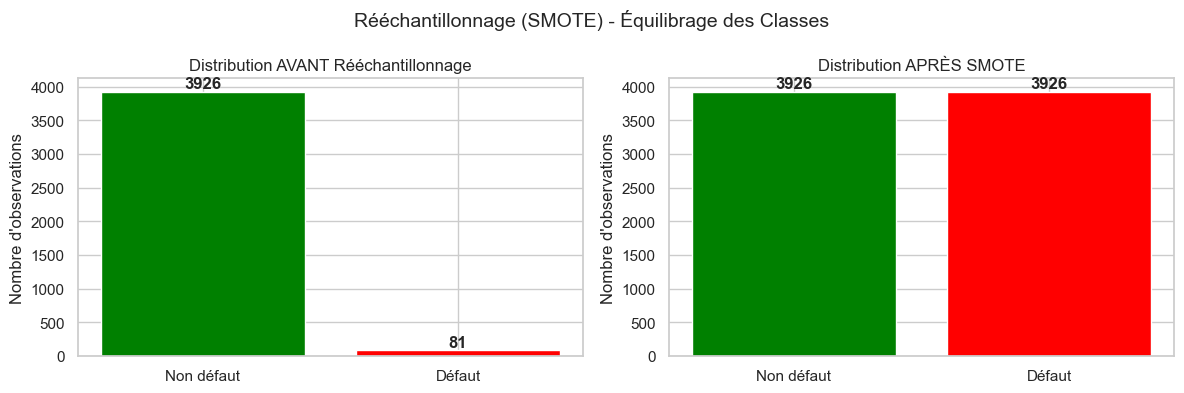

In [56]:
# Visualisation avant/après rééchantillonnage
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

# Avant rééchantillonnage
axes[0].bar(['Non défaut', 'Défaut'], [sum(y_train == 0), sum(y_train == 1)], color=['green', 'red'])
axes[0].set_title('Distribution AVANT Rééchantillonnage')
axes[0].set_ylabel('Nombre d\'observations')
for i, v in enumerate([sum(y_train == 0), sum(y_train == 1)]):
    axes[0].text(i, v + 50, str(v), ha='center', fontweight='bold')

# Après rééchantillonnage
axes[1].bar(['Non défaut', 'Défaut'], [sum(y_train_resampled == 0), sum(y_train_resampled == 1)], color=['green', 'red'])
axes[1].set_title(f'Distribution APRÈS {resampling_method}')
axes[1].set_ylabel('Nombre d\'observations')
for i, v in enumerate([sum(y_train_resampled == 0), sum(y_train_resampled == 1)]):
    axes[1].text(i, v + 50, str(v), ha='center', fontweight='bold')

plt.suptitle(f'Rééchantillonnage ({resampling_method}) - Équilibrage des Classes', fontsize=14)
plt.tight_layout()
plt.show()

## Export des Bases Train/Test

In [57]:
# Export des bases vers Excel
print("=== EXPORT DES DONNÉES VERS EXCEL ===\n")

# Créer les DataFrames pour l'export
df_train = X_train.copy()
df_train['flag_defaut'] = y_train.values

df_test = X_test.copy()
df_test['flag_defaut'] = y_test.values

df_train_resampled = pd.DataFrame(X_train_resampled, columns=X_train.columns)
df_train_resampled['flag_defaut'] = y_train_resampled.values

# Export vers Excel avec plusieurs feuilles
output_file = 'bases_train&test.xlsx'

with pd.ExcelWriter(output_file, engine='openpyxl') as writer:
    df_train.to_excel(writer, sheet_name='Train_Original', index=False)
    df_test.to_excel(writer, sheet_name='Test', index=False)
    df_train_resampled.to_excel(writer, sheet_name='Train_Resampled', index=False)

print(f"✓ Fichier exporté: {output_file}")
print(f"\nContenu du fichier Excel:")
print(f"  • Feuille 'Train_Original': {df_train.shape[0]} lignes x {df_train.shape[1]} colonnes")
print(f"  • Feuille 'Test': {df_test.shape[0]} lignes x {df_test.shape[1]} colonnes")
print(f"  • Feuille 'Train_Resampled' ({resampling_method}): {df_train_resampled.shape[0]} lignes x {df_train_resampled.shape[1]} colonnes")

=== EXPORT DES DONNÉES VERS EXCEL ===

✓ Fichier exporté: bases_train&test.xlsx

Contenu du fichier Excel:
  • Feuille 'Train_Original': 4007 lignes x 33 colonnes
  • Feuille 'Test': 1718 lignes x 33 colonnes
  • Feuille 'Train_Resampled' (SMOTE): 7852 lignes x 33 colonnes


#  ETAPE 5 : SELECTION DES VARIABLES :

---
 Objectif : Identifier les variables les plus **predictives** du risque de defaut.

Calcul de l'Information Value (IV)

L'**Information Value** mesure le pouvoir predictif d'une variable.



In [58]:
# Fonction pour calculer le Weight of Evidence (WoE) et l'Information Value (IV)
def calculate_woe_iv(df, feature, target, bins=10):
    # Copie pour eviter les modifications
    data = df[[feature, target]].copy()
    
    # Si variable continue, discretiser en bins
    if data[feature].dtype in ['float64', 'int64'] and data[feature].nunique() > bins:
        data['bin'] = pd.qcut(data[feature], q=bins, duplicates='drop')
    else:
        data['bin'] = data[feature]
    
    # Calculer les statistiques par bin
    grouped = data.groupby('bin')[target].agg(['count', 'sum'])
    grouped.columns = ['total', 'bad']
    grouped['n_bad'] = grouped['total'] - grouped['bad']
    
    # Eviter division par zero
    grouped['bad'] = grouped['bad'].replace(0, 0.5)
    grouped['n_bad'] = grouped['n_bad'].replace(0, 0.5)
    
    # Calcul des distributions
    total_bad = grouped['bad'].sum()
    total_n_bad = grouped['n_bad'].sum()
    
    grouped['dist_bad'] = grouped['bad'] / total_bad
    grouped['dist_n_bad'] = grouped['n_bad'] / total_n_bad
    
    # Calcul WoE et IV
    grouped['woe'] = np.log(grouped['dist_n_bad'] / grouped['dist_bad'])
    grouped['iv'] = (grouped['dist_n_bad'] - grouped['dist_bad']) * grouped['woe']
    
    iv_total = grouped['iv'].sum()
    
    return grouped, iv_total

print("[OK] Fonction calculate_woe_iv definie")

[OK] Fonction calculate_woe_iv definie


In [59]:
# Calcul de l'IV pour toutes les variables
print("=== CALCUL DE L'INFORMATION VALUE (IV) PAR VARIABLE ===\n")

# Creer df_train en combinant X_train et y_train (avant reechantillonnage pour eviter le biais)
df_train = X_train.copy()
df_train['flag_defaut'] = y_train.values

# Liste des features (exclure la cible)
features = [col for col in df_train.columns if col != 'flag_defaut']

# Calculer l'IV pour chaque variable
iv_results = []

for feature in features:
    try:
        _, iv = calculate_woe_iv(df_train, feature, 'flag_defaut', bins=10)
        iv_results.append({
            'Variable': feature,
            'IV': iv
        })
    except Exception as e:
        print(f"  [ERREUR] Erreur pour {feature}: {e}")

# Creer DataFrame des resultats
df_iv_results = pd.DataFrame(iv_results)
df_iv_results = df_iv_results.sort_values('IV', ascending=False).reset_index(drop=True)

# Ajouter l'interpretation
def interpret_iv(iv):
    if iv < 0.02:
        return "Non predictif"
    elif iv < 0.1:
        return "Faible"
    elif iv < 0.3:
        return "Moyen"
    elif iv < 0.5:
        return "Fort"
    else:
        return "Suspect"

df_iv_results['Interpretation'] = df_iv_results['IV'].apply(interpret_iv)

print(df_iv_results.to_string(index=False))
print(f"\n[OK] Total variables analysees: {len(df_iv_results)}")

=== CALCUL DE L'INFORMATION VALUE (IV) PAR VARIABLE ===

              Variable       IV Interpretation
          Solde_arrete 1.469687        Suspect
         Solde_Revenus 0.779150        Suspect
           Solde_moyen 0.704981        Suspect
               CRD/eng 0.536138        Suspect
           Age_calculé 0.406802           Fort
                   Age 0.406802           Fort
               log_CRD 0.315418           Fort
                   CRD 0.315418           Fort
              Maturite 0.282889          Moyen
          Age_relation 0.276539          Moyen
        log_Engagement 0.270187          Moyen
            Engagement 0.270187          Moyen
    Intensite_Relation 0.263582          Moyen
             CRD_x_Age 0.243253          Moyen
                   DTI 0.212632          Moyen
    Utilisation_Credit 0.210712          Moyen
    Revenus_x_Maturite 0.195534          Moyen
               CRD/gar 0.195268          Moyen
           CRD_Revenus 0.191665          Moyen
   

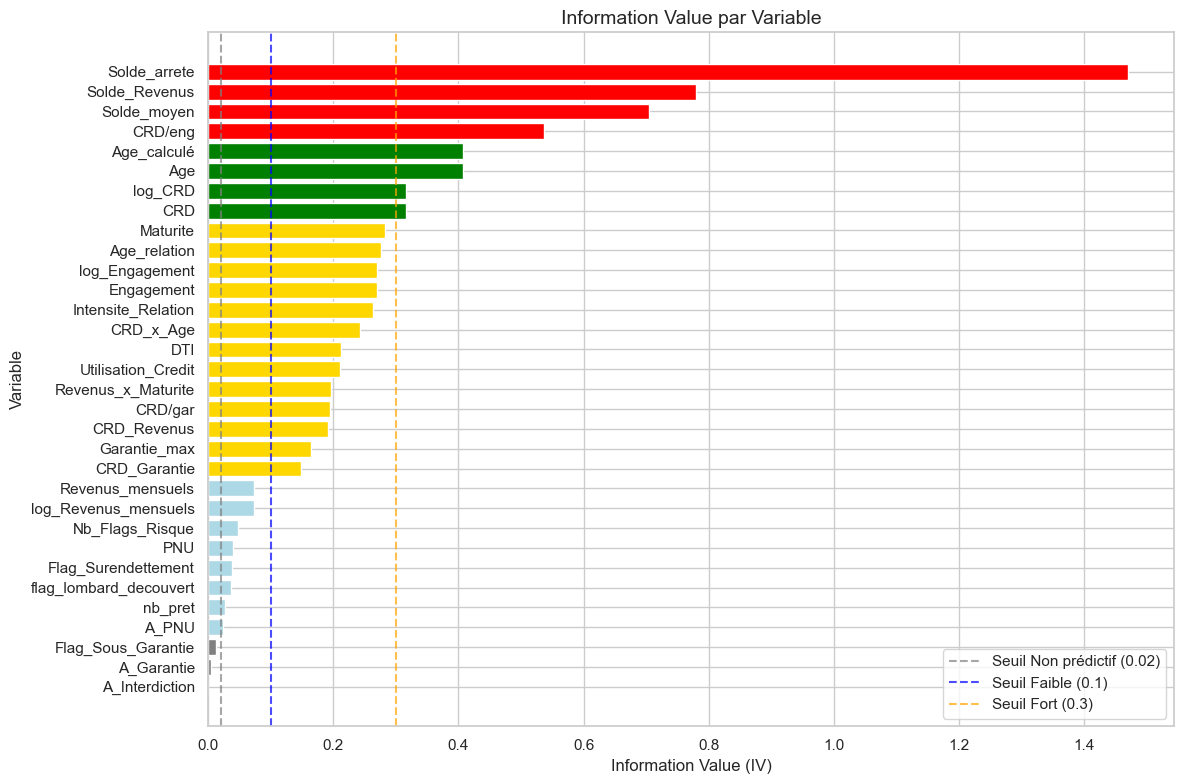

In [60]:
# Visualisation de l'IV par variable
fig, ax = plt.subplots(figsize=(12, 8))

# Couleurs selon l'IV
colors = []
for iv in df_iv_results['IV']:
    if iv < 0.02:
        colors.append('gray')
    elif iv < 0.1:
        colors.append('lightblue')
    elif iv < 0.3:
        colors.append('gold')
    elif iv < 0.5:
        colors.append('green')
    else:
        colors.append('red')

# Barplot horizontal
bars = ax.barh(df_iv_results['Variable'], df_iv_results['IV'], color=colors)
ax.set_xlabel('Information Value (IV)', fontsize=12)
ax.set_ylabel('Variable', fontsize=12)
ax.set_title('Information Value par Variable', fontsize=14)

# Lignes de seuil
ax.axvline(x=0.02, color='gray', linestyle='--', alpha=0.7, label='Seuil Non prédictif (0.02)')
ax.axvline(x=0.1, color='blue', linestyle='--', alpha=0.7, label='Seuil Faible (0.1)')
ax.axvline(x=0.3, color='orange', linestyle='--', alpha=0.7, label='Seuil Fort (0.3)')

ax.legend(loc='lower right')
ax.invert_yaxis()  # Plus grande IV en haut

plt.tight_layout()
plt.show()

# Selection des Variables Pertinentes (IV >= 0.02)

> Filtrage des variables selon leur pouvoir predictif.

In [61]:
# Selection des variables pertinentes
print("=== SELECTION DES VARIABLES PERTINENTES ===\n")

# Seuil minimum d'IV
iv_threshold = 0.02

# Variables selectionnees
vars_selected = df_iv_results[df_iv_results['IV'] >= iv_threshold]['Variable'].tolist()
vars_rejected = df_iv_results[df_iv_results['IV'] < iv_threshold]['Variable'].tolist()

print(f"Seuil IV minimum: {iv_threshold}")
print(f"\n[OK] Variables SELECTIONNEES ({len(vars_selected)}):")
for var in vars_selected:
    iv = df_iv_results[df_iv_results['Variable'] == var]['IV'].values[0]
    interp = df_iv_results[df_iv_results['Variable'] == var]['Interpretation'].values[0]
    print(f"   - {var}: IV = {iv:.4f} ({interp})")

print(f"\n[X] Variables REJETEES ({len(vars_rejected)}):")
for var in vars_rejected:
    iv = df_iv_results[df_iv_results['Variable'] == var]['IV'].values[0]
    print(f"   - {var}: IV = {iv:.4f}")

=== SELECTION DES VARIABLES PERTINENTES ===

Seuil IV minimum: 0.02

[OK] Variables SELECTIONNEES (29):
   - Solde_arrete: IV = 1.4697 (Suspect)
   - Solde_Revenus: IV = 0.7792 (Suspect)
   - Solde_moyen: IV = 0.7050 (Suspect)
   - CRD/eng: IV = 0.5361 (Suspect)
   - Age_calculé: IV = 0.4068 (Fort)
   - Age: IV = 0.4068 (Fort)
   - log_CRD: IV = 0.3154 (Fort)
   - CRD: IV = 0.3154 (Fort)
   - Maturite: IV = 0.2829 (Moyen)
   - Age_relation: IV = 0.2765 (Moyen)
   - log_Engagement: IV = 0.2702 (Moyen)
   - Engagement: IV = 0.2702 (Moyen)
   - Intensite_Relation: IV = 0.2636 (Moyen)
   - CRD_x_Age: IV = 0.2433 (Moyen)
   - DTI: IV = 0.2126 (Moyen)
   - Utilisation_Credit: IV = 0.2107 (Moyen)
   - Revenus_x_Maturite: IV = 0.1955 (Moyen)
   - CRD/gar: IV = 0.1953 (Moyen)
   - CRD_Revenus: IV = 0.1917 (Moyen)
   - Garantie_max: IV = 0.1638 (Moyen)
   - CRD_Garantie: IV = 0.1482 (Moyen)
   - Revenus_mensuels: IV = 0.0737 (Faible)
   - log_Revenus_mensuels: IV = 0.0737 (Faible)
   - Nb_Flags_

 # Traitement de la Multicollinearite

> Suppression des variables fortement correlees (|r| > 0.7) pour eviter l'instabilite du modele.


=== ÉTUDE DE LA DÉPENDANCE ENTRE VARIABLES (CORRÉLATION) ===



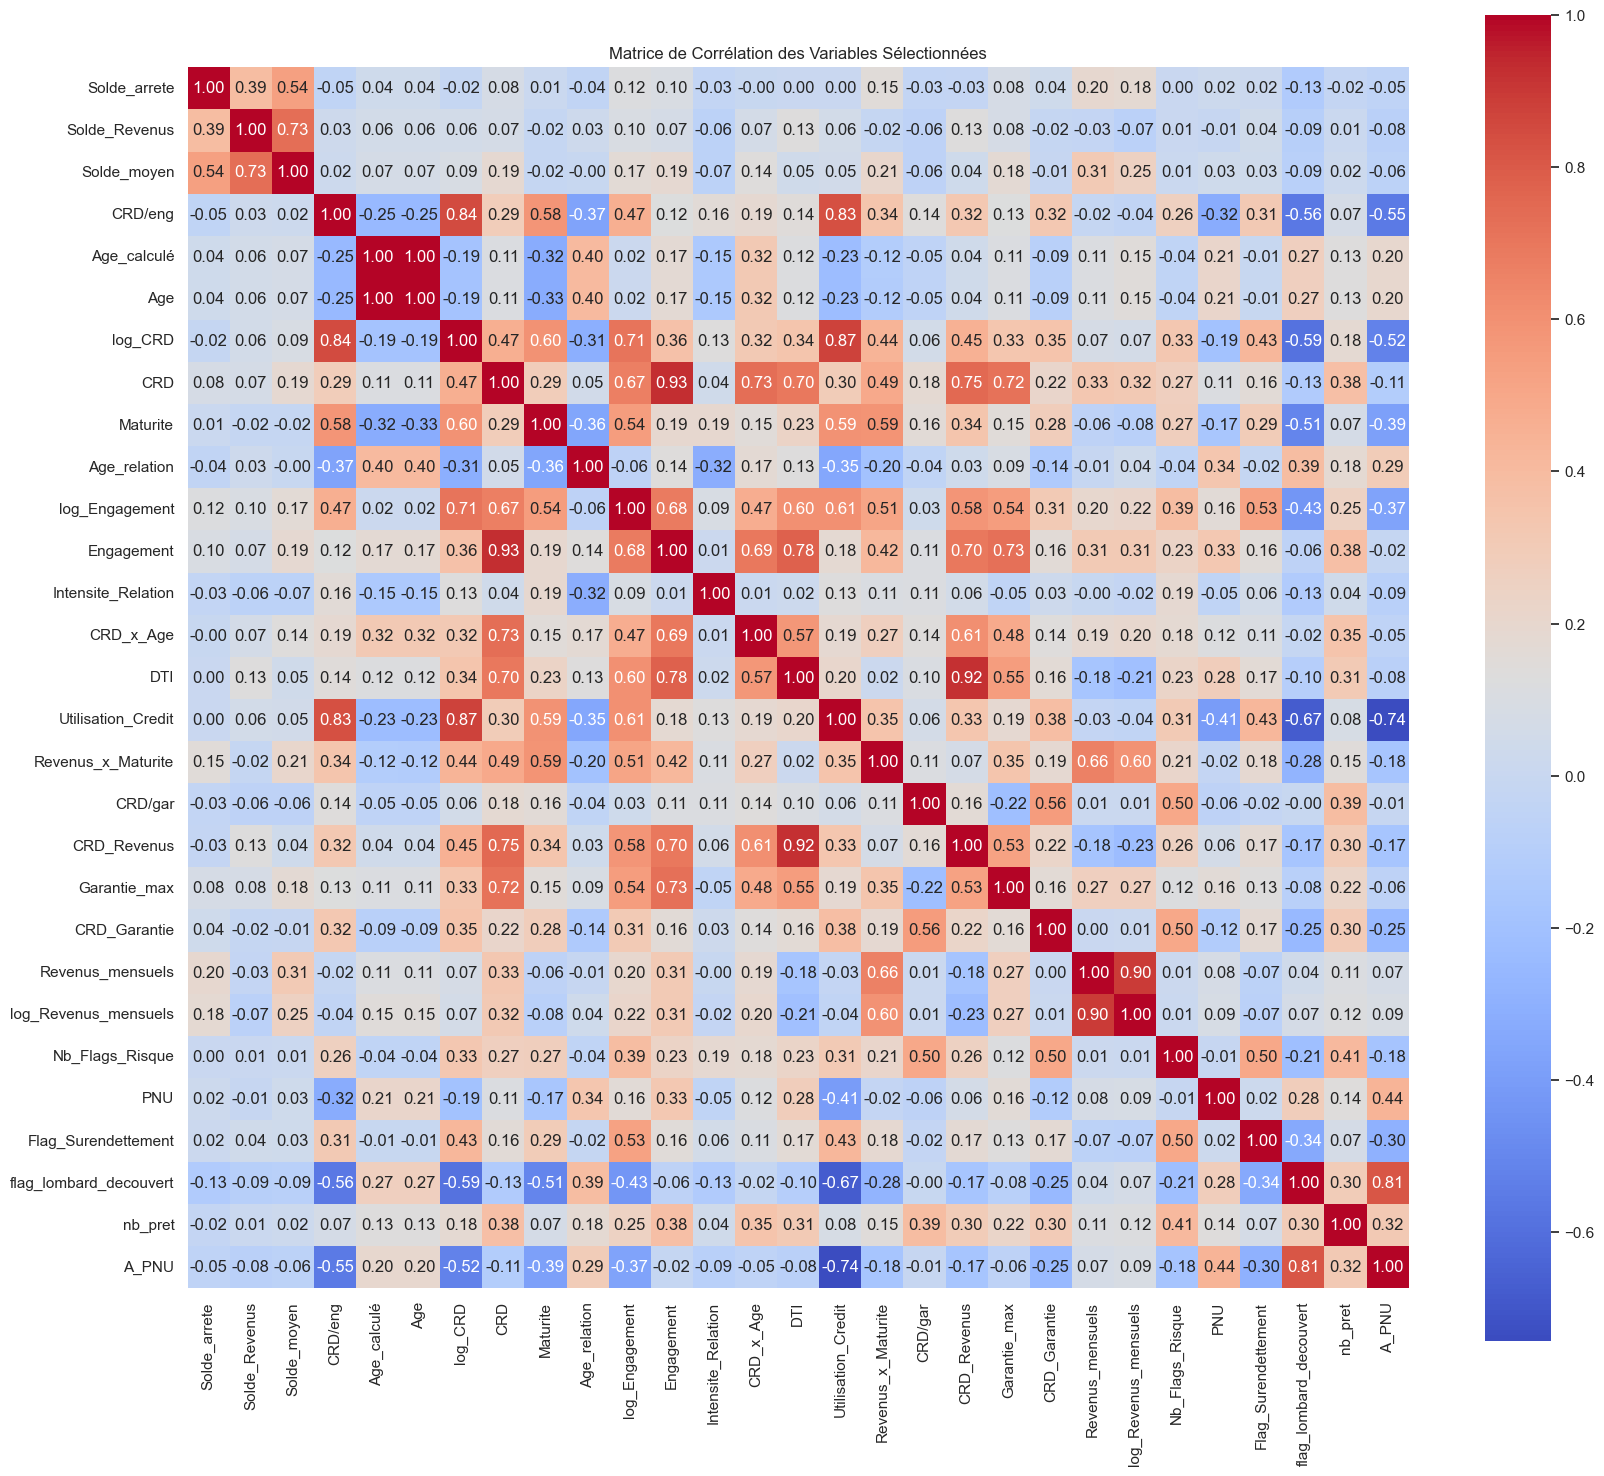

Variables fortement corrélées (|corrélation| > 0.75):
   - Age et Age_calculé: corrélation = 1.00
   - log_CRD et CRD/eng: corrélation = 0.84
   - Engagement et CRD: corrélation = 0.93
   - DTI et Engagement: corrélation = 0.78
   - Utilisation_Credit et CRD/eng: corrélation = 0.83
   - Utilisation_Credit et log_CRD: corrélation = 0.87
   - CRD_Revenus et CRD: corrélation = 0.75
   - CRD_Revenus et DTI: corrélation = 0.92
   - log_Revenus_mensuels et Revenus_mensuels: corrélation = 0.90
   - A_PNU et flag_lombard_decouvert: corrélation = 0.81


In [62]:
# Étude de la dépendance entre variables (corrélation)
print("\n=== ÉTUDE DE LA DÉPENDANCE ENTRE VARIABLES (CORRÉLATION) ===\n")
# Calcul de la matrice de corrélation
vars_for_corr = [v for v in vars_selected if v in df_train.columns]
corr_matrix = df_train[vars_for_corr].corr()
# Visualisation de la matrice de corrélation
n_vars = len(vars_for_corr)
fig_size = max(16, n_vars * 0.6)
plt.figure(figsize=(fig_size, fig_size))
sns.heatmap(corr_matrix, annot=True, fmt=".2f", cmap='coolwarm', square=True, cbar_kws={"shrink": .8})
plt.title('Matrice de Corrélation des Variables Sélectionnées')
plt.tight_layout()
plt.show()
#affichage des paires de variables fortement corrélées
threshold_corr = 0.75
high_corr_pairs = []
for i in range(len(corr_matrix.columns)):
    for j in range(i):
        if abs(corr_matrix.iloc[i, j]) > threshold_corr:
            var1 = corr_matrix.columns[i]
            var2 = corr_matrix.columns[j]
            corr_value = corr_matrix.iloc[i, j]
            high_corr_pairs.append((var1, var2, corr_value))
if high_corr_pairs:
    print(f"Variables fortement corrélées (|corrélation| > {threshold_corr}):")
    for var1, var2, corr_value in high_corr_pairs:
        print(f"   - {var1} et {var2}: corrélation = {corr_value:.2f}")





In [63]:
# Traitement des variables correlees - garder celle avec le plus grand IV
print("=== SELECTION FINALE APRES TRAITEMENT DES CORRELATIONS ===\n")
vars_to_remove = set()
for var1, var2, corr_value in high_corr_pairs:
    iv1 = df_iv_results[df_iv_results['Variable'] == var1]['IV'].values[0]
    iv2 = df_iv_results[df_iv_results['Variable'] == var2]['IV'].values[0]
    if iv1 >= iv2:
        vars_to_remove.add(var2)
        print(f"   - Retirer {var2} (IV={iv2:.4f}) au profit de {var1} (IV={iv1:.4f})")
    else:
        vars_to_remove.add(var1)
        print(f"   - Retirer {var1} (IV={iv1:.4f}) au profit de {var2} (IV={iv2:.4f})")
vars_final = [v for v in vars_selected if v not in vars_to_remove]
print(f"\n[OK] Variables finales retenues ({len(vars_final)}):")
for var in vars_final:
    iv = df_iv_results[df_iv_results['Variable'] == var]['IV'].values[0]
    interp = df_iv_results[df_iv_results['Variable'] == var]['Interpretation'].values[0]
    print(f"   - {var}: IV = {iv:.4f} ({interp})")
    




=== SELECTION FINALE APRES TRAITEMENT DES CORRELATIONS ===

   - Retirer Age_calculé (IV=0.4068) au profit de Age (IV=0.4068)
   - Retirer log_CRD (IV=0.3154) au profit de CRD/eng (IV=0.5361)
   - Retirer Engagement (IV=0.2702) au profit de CRD (IV=0.3154)
   - Retirer DTI (IV=0.2126) au profit de Engagement (IV=0.2702)
   - Retirer Utilisation_Credit (IV=0.2107) au profit de CRD/eng (IV=0.5361)
   - Retirer Utilisation_Credit (IV=0.2107) au profit de log_CRD (IV=0.3154)
   - Retirer CRD_Revenus (IV=0.1917) au profit de CRD (IV=0.3154)
   - Retirer CRD_Revenus (IV=0.1917) au profit de DTI (IV=0.2126)
   - Retirer Revenus_mensuels (IV=0.0737) au profit de log_Revenus_mensuels (IV=0.0737)
   - Retirer A_PNU (IV=0.0244) au profit de flag_lombard_decouvert (IV=0.0373)

[OK] Variables finales retenues (21):
   - Solde_arrete: IV = 1.4697 (Suspect)
   - Solde_Revenus: IV = 0.7792 (Suspect)
   - Solde_moyen: IV = 0.7050 (Suspect)
   - CRD/eng: IV = 0.5361 (Suspect)
   - Age: IV = 0.4068 (Fort

# Export des Resultats IV: 

In [64]:

# Export des résultats IV et corrélations vers Excel
print("=== EXPORT DES RÉSULTATS VERS EXCEL ===\n")
output_excel_path = "resultats_selection.xlsx"
# Ajouter colonne de sélection
df_iv_results['Sélectionnée'] = df_iv_results['Variable'].apply(
    lambda x: 'OUI' if x in vars_final else ('CORRÉLÉE' if x in vars_to_remove else 'NON')
)
with pd.ExcelWriter(output_excel_path, engine='openpyxl') as writer:
    # Feuille 1: IV par variable
    df_iv_results.to_excel(writer, sheet_name='IV_par_Variable', index=False)
    
    # Feuille 2: Matrice de corrélation
    corr_matrix.to_excel(writer, sheet_name='Matrice_Correlation')
    
    # Feuille 3: Paires corrélées
    if high_corr_pairs:
        pd.DataFrame(high_corr_pairs).to_excel(writer, sheet_name='Paires_Correlees', index=False)
    
    # Feuille 4: Variables finales
    df_final_vars = df_iv_results[df_iv_results['Variable'].isin(vars_final)][['Variable', 'IV', 'Interpretation']]
    df_final_vars.to_excel(writer, sheet_name='Variables_Finales', index=False)
print(f"✓ Fichier exporté: {output_excel_path}")




=== EXPORT DES RÉSULTATS VERS EXCEL ===

✓ Fichier exporté: resultats_selection.xlsx


# ETAPE 6 : MODELISATION - REGRESSION LOGISTIQUE

---

> Construction du modele de scoring et de la scorecard finale.

## Preparation du Modele:

In [65]:
# Installation de statsmodels (alternative robuste à sklearn pour la régression logistique)
import subprocess
import sys

# Installer statsmodels si nécessaire
try:
    import statsmodels.api as sm
    print("✓ statsmodels déjà installé")
except ImportError:
    print("Installation de statsmodels...")
    subprocess.check_call([sys.executable, "-m", "pip", "install", "statsmodels", "-q"])
    import statsmodels.api as sm
    print("✓ statsmodels installé")

import warnings
warnings.filterwarnings('ignore')

print("\n=== PRÉPARATION DU MODÈLE DE RÉGRESSION LOGISTIQUE ===\n")

# Utiliser les variables finales sélectionnées à l'étape 3
print(f"Variables utilisées pour le modèle ({len(vars_final)}):")
for i, var in enumerate(vars_final, 1):
    print(f"   {i}. {var}")

# Préparer les données avec les variables sélectionnées
X_train_model = X_train_resampled[vars_final].copy()
X_test_model = X_test[vars_final].copy()

# Ajouter la constante (intercept) pour statsmodels
X_train_model = sm.add_constant(X_train_model)
X_test_model = sm.add_constant(X_test_model)

print(f"\n✓ Données d'entraînement: {X_train_model.shape}")
print(f"✓ Données de test: {X_test_model.shape}")

✓ statsmodels déjà installé

=== PRÉPARATION DU MODÈLE DE RÉGRESSION LOGISTIQUE ===

Variables utilisées pour le modèle (21):
   1. Solde_arrete
   2. Solde_Revenus
   3. Solde_moyen
   4. CRD/eng
   5. Age
   6. CRD
   7. Maturite
   8. Age_relation
   9. log_Engagement
   10. Intensite_Relation
   11. CRD_x_Age
   12. Revenus_x_Maturite
   13. CRD/gar
   14. Garantie_max
   15. CRD_Garantie
   16. log_Revenus_mensuels
   17. Nb_Flags_Risque
   18. PNU
   19. Flag_Surendettement
   20. flag_lombard_decouvert
   21. nb_pret

✓ Données d'entraînement: (7852, 22)
✓ Données de test: (1718, 22)


# Entrainement du modele 

In [66]:
# Vérification et nettoyage des données avant modélisation
print("=== VÉRIFICATION DES DONNÉES AVANT MODÉLISATION ===\n")

# Vérifier les valeurs manquantes et infinies
print("Valeurs manquantes dans X_train_model:")
print(X_train_model.isnull().sum()[X_train_model.isnull().sum() > 0])

print("\nValeurs infinies dans X_train_model:")
inf_counts = np.isinf(X_train_model.select_dtypes(include=[np.number])).sum()
print(inf_counts[inf_counts > 0])

# Remplacer les valeurs infinies par les valeurs max/min raisonnables
for col in X_train_model.columns:
    if col != 'const':
        # Remplacer inf par le 99e percentile
        if np.isinf(X_train_model[col]).any():
            max_val = X_train_model[col][~np.isinf(X_train_model[col])].max()
            min_val = X_train_model[col][~np.isinf(X_train_model[col])].min()
            X_train_model.loc[X_train_model[col] == np.inf, col] = max_val
            X_train_model.loc[X_train_model[col] == -np.inf, col] = min_val
            print(f"  {col}: valeurs inf remplacées")
        
        # Remplacer NaN par la médiane
        if X_train_model[col].isnull().any():
            median_val = X_train_model[col].median()
            X_train_model[col] = X_train_model[col].fillna(median_val)
            print(f"  {col}: NaN remplacés par médiane ({median_val:.2f})")

# Même traitement pour X_test_model
for col in X_test_model.columns:
    if col != 'const':
        if np.isinf(X_test_model[col]).any():
            max_val = X_test_model[col][~np.isinf(X_test_model[col])].max()
            min_val = X_test_model[col][~np.isinf(X_test_model[col])].min()
            X_test_model.loc[X_test_model[col] == np.inf, col] = max_val
            X_test_model.loc[X_test_model[col] == -np.inf, col] = min_val
        if X_test_model[col].isnull().any():
            median_val = X_test_model[col].median()
            X_test_model[col] = X_test_model[col].fillna(median_val)

print("\n✓ Données nettoyées et prêtes pour la modélisation")
print(f"  X_train_model: {X_train_model.shape}")
print(f"  X_test_model: {X_test_model.shape}")

=== VÉRIFICATION DES DONNÉES AVANT MODÉLISATION ===

Valeurs manquantes dans X_train_model:
Series([], dtype: int64)

Valeurs infinies dans X_train_model:
Series([], dtype: int64)

✓ Données nettoyées et prêtes pour la modélisation
  X_train_model: (7852, 22)
  X_test_model: (1718, 22)


In [67]:
# Entraînement du modèle de régression logistique
print("=== ENTRAÎNEMENT DU MODÈLE DE RÉGRESSION LOGISTIQUE ===\n")

# Diagnostic des données
print(f"Distribution y_train_resampled: {y_train_resampled.value_counts().to_dict()}")
print(f"Type y_train_resampled: {type(y_train_resampled)}")

# Vérifier et supprimer les colonnes constantes ou quasi-constantes
cols_to_remove = []
for col in X_train_model.columns:
    if col != 'const':
        if X_train_model[col].std() < 1e-10:
            cols_to_remove.append(col)
            print(f"⚠️ Colonne {col} quasi-constante - supprimée")

if cols_to_remove:
    X_train_model = X_train_model.drop(columns=cols_to_remove)
    X_test_model = X_test_model.drop(columns=cols_to_remove)
    print(f"\n✓ {len(cols_to_remove)} colonnes supprimées")

# Standardiser les features pour améliorer la convergence
from sklearn.preprocessing import StandardScaler

# Séparer la constante
X_train_features = X_train_model.drop(columns=['const'])
X_test_features = X_test_model.drop(columns=['const'])

# Standardiser
scaler = StandardScaler()
X_train_scaled = scaler.fit_transform(X_train_features)
X_test_scaled = scaler.transform(X_test_features)

# Recréer les DataFrames avec constante
X_train_scaled_df = pd.DataFrame(X_train_scaled, columns=X_train_features.columns)
X_train_scaled_df = sm.add_constant(X_train_scaled_df)

X_test_scaled_df = pd.DataFrame(X_test_scaled, columns=X_test_features.columns)
X_test_scaled_df = sm.add_constant(X_test_scaled_df)

print(f"\n✓ Features standardisées pour meilleure convergence")

# Créer et entraîner le modèle avec statsmodels
model = sm.Logit(y_train_resampled.values, X_train_scaled_df)

# Fit du modèle avec méthode BFGS (plus robuste)
result = model.fit(method='bfgs', maxiter=500, disp=False)

# Afficher le résumé complet du modèle
print(result.summary())

# Afficher les statistiques clés
print("\n" + "=" * 70)
print("                    STATISTIQUES DU MODÈLE")
print("=" * 70)
print(f"Pseudo R² (McFadden):     {result.prsquared:.4f}")
print(f"Log-Likelihood:           {result.llf:.2f}")
print(f"AIC:                      {result.aic:.2f}")
print(f"BIC:                      {result.bic:.2f}")
print(f"Nombre d'observations:    {int(result.nobs)}")

# Stocker les données pour les prédictions (on garde les non-standardisées pour l'interprétation)
X_train_model_final = X_train_scaled_df
X_test_model_final = X_test_scaled_df

=== ENTRAÎNEMENT DU MODÈLE DE RÉGRESSION LOGISTIQUE ===

Distribution y_train_resampled: {1.0: 3926, 0.0: 3926}
Type y_train_resampled: <class 'pandas.core.series.Series'>

✓ Features standardisées pour meilleure convergence
                           Logit Regression Results                           
Dep. Variable:                      y   No. Observations:                 7852
Model:                          Logit   Df Residuals:                     7830
Method:                           MLE   Df Model:                           21
Date:                Wed, 24 Dec 2025   Pseudo R-squ.:                  0.3176
Time:                        14:28:28   Log-Likelihood:                -3713.8
converged:                       True   LL-Null:                       -5442.6
Covariance Type:            nonrobust   LLR p-value:                     0.000
                             coef    std err          z      P>|z|      [0.025      0.975]
----------------------------------------------------

# Analyse des Coefficients & Odds Ratios 

In [72]:
# Analyse détaillée des coefficients
print("=== ANALYSE DES COEFFICIENTS DU MODÈLE ===\n")

# Créer un DataFrame des coefficients
coef_df = pd.DataFrame({
    'Variable': result.params.index,
    'Coefficient': result.params.values,
    'Std Error': result.bse.values,
    'z-stat': result.tvalues.values,
    'P-value': result.pvalues.values,
    'Odds Ratio': np.exp(result.params.values)
})

# Trier par valeur absolue du coefficient
coef_df = coef_df.sort_values('Coefficient', key=abs, ascending=False)

# Ajouter indicateur de significativité
def significance(p):
    if p < 0.001:
        return '***'
    elif p < 0.01:
        return '**'
    elif p < 0.05:
        return '*'
    elif p < 0.1:
        return '.'
    else:
        return ''

coef_df['Signif.'] = coef_df['P-value'].apply(significance)

print(coef_df.to_string(index=False))
print("\n--- Légende ---")
print("*** p < 0.001 | ** p < 0.01 | * p < 0.05 | . p < 0.1")

# Compter les variables significatives
n_signif = (coef_df['P-value'] < 0.05).sum() - 1  # -1 pour la constante
print(f"\n✓ Variables significatives (p < 0.05): {n_signif} / {len(vars_final)}")

=== ANALYSE DES COEFFICIENTS DU MODÈLE ===

              Variable  Coefficient  Std Error     z-stat      P-value  Odds Ratio Signif.
         Solde_Revenus    -4.058492   0.322950 -12.566955 3.208430e-36    0.017275     ***
   Flag_Surendettement     1.779573   7.967054   0.223367 8.232503e-01    5.927326        
          Solde_arrete    -0.911410   0.060063 -15.174198 5.241437e-52    0.401957     ***
                 const    -0.856891   0.981015  -0.873473 3.824052e-01    0.424480        
flag_lombard_decouvert    -0.764848   0.052955 -14.443253 2.764804e-47    0.465405     ***
              Maturite    -0.739443   0.068398 -10.810884 3.057091e-27    0.477380     ***
    Intensite_Relation    -0.730708   0.058843 -12.417893 2.089922e-35    0.481568     ***
       Nb_Flags_Risque    -0.712741   0.049274 -14.464724 2.024139e-47    0.490299     ***
                   CRD    -0.593068   0.094948  -6.246260 4.203965e-10    0.552629     ***
          Garantie_max     0.492825   0.075361


=== INTERPRETATION DU MODELE DE NOTATION ===



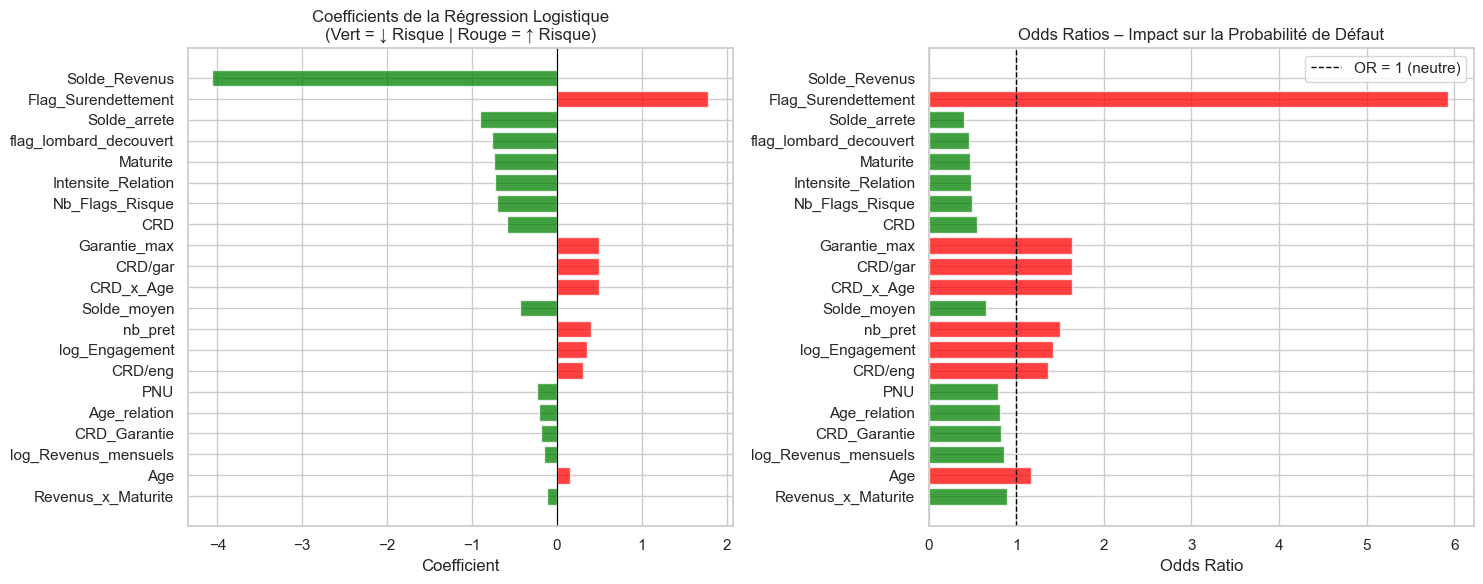


=== INTERPRÉTATION DES VARIABLES SIGNIFICATIVES (p < 5%) ===

• Solde_Revenus (OR = 0.0173)
  → Une augmentation d'une unité diminue le risque de défaut de 98.3%

• Solde_arrete (OR = 0.4020)
  → Une augmentation d'une unité diminue le risque de défaut de 59.8%

• flag_lombard_decouvert (OR = 0.4654)
  → Une augmentation d'une unité diminue le risque de défaut de 53.5%

• Maturite (OR = 0.4774)
  → Une augmentation d'une unité diminue le risque de défaut de 52.3%

• Intensite_Relation (OR = 0.4816)
  → Une augmentation d'une unité diminue le risque de défaut de 51.8%

• Nb_Flags_Risque (OR = 0.4903)
  → Une augmentation d'une unité diminue le risque de défaut de 51.0%

• CRD (OR = 0.5526)
  → Une augmentation d'une unité diminue le risque de défaut de 44.7%

• Garantie_max (OR = 1.6369)
  → Une augmentation d'une unité augmente le risque de défaut de 63.7%

• CRD/gar (OR = 1.6332)
  → Une augmentation d'une unité augmente le risque de défaut de 63.3%

• CRD_x_Age (OR = 1.6326)
  → Une

In [73]:

print("\n=== INTERPRETATION DU MODELE DE NOTATION ===\n")

# --------------------------------
# 1. Préparation des données
# --------------------------------
coef_analysis = coef_df.copy()
coef_analysis = coef_analysis[coef_analysis['Variable'] != 'const']

# Limiter les OR extrêmes pour lisibilité graphique
coef_analysis['Odds Ratio Capped'] = coef_analysis['Odds Ratio'].clip(upper=100)

# --------------------------------
# 2. Visualisation : Coefficients & Odds Ratios
# --------------------------------
fig, axes = plt.subplots(1, 2, figsize=(15, 6))

# --- Graphique 1 : Coefficients
ax1 = axes[0]
colors_coef = ['green' if c < 0 else 'red' for c in coef_analysis['Coefficient']]
ax1.barh(coef_analysis['Variable'], coef_analysis['Coefficient'],
         color=colors_coef, alpha=0.75)
ax1.axvline(x=0, color='black', linewidth=0.8)
ax1.set_title('Coefficients de la Régression Logistique\n(Vert = ↓ Risque | Rouge = ↑ Risque)')
ax1.set_xlabel('Coefficient')
ax1.invert_yaxis()

# --- Graphique 2 : Odds Ratios
ax2 = axes[1]
colors_or = ['green' if o < 1 else 'red' for o in coef_analysis['Odds Ratio']]
ax2.barh(coef_analysis['Variable'], coef_analysis['Odds Ratio Capped'],
         color=colors_or, alpha=0.75)
ax2.axvline(x=1, color='black', linestyle='--', linewidth=1, label='OR = 1 (neutre)')
ax2.set_title('Odds Ratios – Impact sur la Probabilité de Défaut')
ax2.set_xlabel('Odds Ratio')
ax2.legend()
ax2.invert_yaxis()

plt.tight_layout()
plt.show()

# --------------------------------
# 3. Interprétation des variables significatives
# --------------------------------
print("\n=== INTERPRÉTATION DES VARIABLES SIGNIFICATIVES (p < 5%) ===\n")

signif_coef = coef_analysis[coef_analysis['P-value'] < 0.05]

if signif_coef.empty:
    print("Aucune variable statistiquement significative au seuil de 5%.")
else:
    for _, row in signif_coef.iterrows():
        var = row['Variable']
        or_val = row['Odds Ratio']

        if or_val > 1:
            pct_change = (or_val - 1) * 100
            print(f"• {var} (OR = {or_val:.4f})")
            print(f"  → Une augmentation d'une unité augmente le risque de défaut de {pct_change:.1f}%")
        else:
            pct_change = (1 - or_val) * 100
            print(f"• {var} (OR = {or_val:.4f})")
            print(f"  → Une augmentation d'une unité diminue le risque de défaut de {pct_change:.1f}%")
        print()


# PREDICTIONS & EVALUATION DU MODELE DE NOTATION

[OK] Probabilités de défaut prédites

--- Statistiques descriptives des PD prédites ---
           PD_train       PD_test
count  7.852000e+03  1.718000e+03
mean   5.000007e-01  3.168426e-01
std    3.020369e-01  2.659764e-01
min    2.070297e-67  1.137199e-44
25%    2.466908e-01  5.371973e-02
50%    5.394347e-01  2.953103e-01
75%    7.433914e-01  5.285509e-01
max    9.999738e-01  9.985469e-01


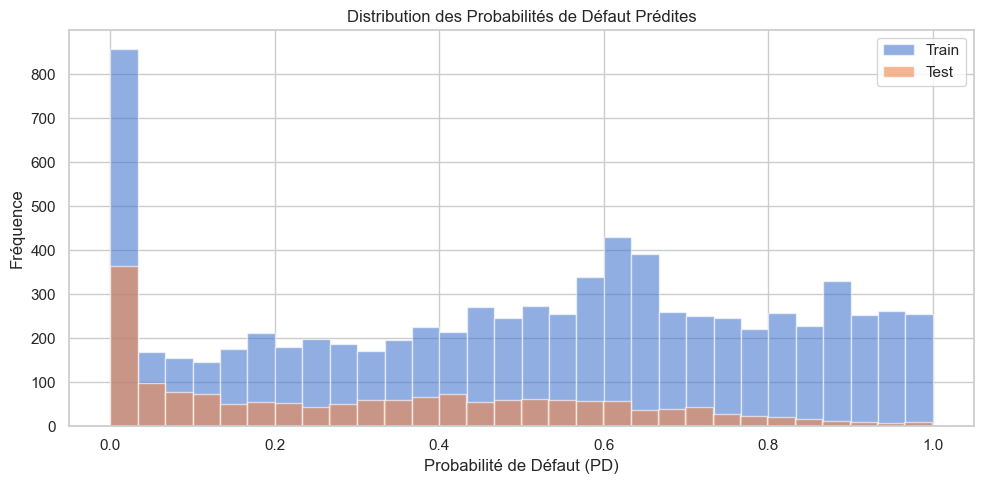

In [78]:
from sklearn.metrics import (
    roc_auc_score, roc_curve,
    confusion_matrix, classification_report
)
# ------------------------------------------------
# 1. Prédiction des probabilités de défaut (PD)
# ------------------------------------------------
y_train=X_train_model_final
y_test=X_test_model_final
y_train_pred_proba = result.predict(X_train_model_final)
y_test_pred_proba = result.predict(X_test_model_final)

print("[OK] Probabilités de défaut prédites")

# ------------------------------------------------
# 2. Analyse descriptive des PD prédites
# ------------------------------------------------
pd_analysis = pd.DataFrame({
    'PD_train': y_train_pred_proba,
    'PD_test': y_test_pred_proba
})

print("\n--- Statistiques descriptives des PD prédites ---")
print(pd_analysis.describe())

# Histogramme des PD
plt.figure(figsize=(10, 5))
plt.hist(y_train_pred_proba, bins=30, alpha=0.6, label='Train')
plt.hist(y_test_pred_proba, bins=30, alpha=0.6, label='Test')
plt.xlabel('Probabilité de Défaut (PD)')
plt.ylabel('Fréquence')
plt.title('Distribution des Probabilités de Défaut Prédites')
plt.legend()
plt.tight_layout()
plt.show()

# ------------------------------------------------
# 3. Courbe ROC & AUC
# ------------------------------------------------
auc_train = roc_auc_score(y_train, y_train_pred_proba)
auc_test = roc_auc_score(y_test, y_test_pred_proba)

fpr_train, tpr_train, _ = roc_curve(y_train, y_train_pred_proba)
fpr_test, tpr_test, _ = roc_curve(y_test, y_test_pred_proba)

plt.figure(figsize=(8, 6))
plt.plot(fpr_train, tpr_train, label=f'Train AUC = {auc_train:.3f}')
plt.plot(fpr_test, tpr_test, linestyle='--', label=f'Test AUC = {auc_test:.3f}')
plt.plot([0, 1], [0, 1], color='grey', linestyle=':')
plt.xlabel('Taux de Faux Positifs')
plt.ylabel('Taux de Vrais Positifs')
plt.title('Courbe ROC – Modèle de Notation')
plt.legend()
plt.tight_layout()
plt.show()

print(f"AUC Train : {auc_train:.3f}")
print(f"AUC Test  : {auc_test:.3f}")

# Gini (standard bancaire)
gini_train = 2 * auc_train - 1
gini_test = 2 * auc_test - 1

print(f"Gini Train : {gini_train:.3f}")
print(f"Gini Test  : {gini_test:.3f}")

# ------------------------------------------------
# 4. KS (Kolmogorov-Smirnov)
# ------------------------------------------------
def ks_statistic(y_true, y_pred):
    data = pd.DataFrame({'y': y_true, 'pd': y_pred})
    data = data.sort_values('pd')
    data['cum_good'] = np.cumsum(1 - data['y']) / sum(1 - data['y'])
    data['cum_bad'] = np.cumsum(data['y']) / sum(data['y'])
    return np.max(np.abs(data['cum_bad'] - data['cum_good']))

ks_train = ks_statistic(y_train, y_train_pred_proba)
ks_test = ks_statistic(y_test, y_test_pred_proba)

print(f"KS Train : {ks_train:.3f}")
print(f"KS Test  : {ks_test:.3f}")

# ------------------------------------------------
# 5. Matrice de confusion & classification
# ------------------------------------------------
# Seuil standard (5% PD – ajustable selon politique risque)
threshold = 0.5

y_test_pred_class = (y_test_pred_proba >= threshold).astype(int)

cm = confusion_matrix(y_test, y_test_pred_class)

print("\n--- Matrice de confusion (Test) ---")
print(cm)

print("\n--- Rapport de classification (Test) ---")
print(classification_report(y_test, y_test_pred_class, digits=3))